# 😴 Ứng dụng YOLOv8 phát hiện ngủ gật — Notebook Google Colab

**Đồ án kết thúc học phần Xử Lí Ảnh.** Notebook này đi theo đúng cấu trúc báo cáo:

| Phần | Nội dung | Mục tương ứng trong báo cáo |
|---|---|---|
| 0 | Cài đặt, cấu hình, kết nối Drive | 3.1 |
| 1 | Nạp video normal/yawn/drowsy → tự tách khung hình, tự gán nhãn, kiểm tra bằng mắt | 2.2, 2.3 |
| 2 | Kiểm tra nhãn, thống kê dữ liệu, histogram độ sáng | 2.4, 2.5 |
| 3 | Xử lý ảnh truyền thống: HSV, CLAHE | 2.5.1, 2.5.2 |
| 4 | Chia tập theo phiên chụp, kiểm tra rò rỉ dữ liệu | 2.6 |
| 5 | Huấn luyện YOLOv8, biểu đồ huấn luyện | 3.2, 3.3, 4.3 |
| 6 | Đánh giá định lượng, ma trận nhầm lẫn, đường cong P/R/F1 | 4.2, 4.4, 4.5 |
| 7 | Ảnh trước/sau và phân tích trường hợp thất bại | 4.6, 4.7 |
| 8 | Thí nghiệm CLAHE trong điều kiện thiếu sáng | 4.6.1 |
| 9 | Thí nghiệm đối chứng (tùy chọn, tốn thời gian) | Bảng 4.3 |
| 10 | Đo tốc độ (ms, FPS) | Bảng 4.4 |
| 11 | Logic cảnh báo theo thời gian + xử lý video | 3.5, 4.9 |
| 12 | Giao diện demo Gradio | 4.8 |
| 13 | Xuất mô hình, lưu kết quả, tóm tắt để dán vào báo cáo | Phụ lục A |

**Cách dùng:** Runtime → Change runtime type → **GPU (T4)**, rồi chạy lần lượt từ trên xuống.
Mọi hình, bảng, mô hình được lưu vào Google Drive (thư mục `report_assets/`, `runs/`, `models/`).

**Dữ liệu đầu vào chỉ là video.** Đặt tên `normal.mp4`, `yawn.mp4`, `drowsy.mp4` (hoặc `an_normal.mp4`, `an_yawn.mp4`, ... nếu có nhiều người: phần đứng trước tên lớp là người/phiên).
Chép vào `MyDrive/drowsiness_yolov8/videos/` hoặc để trống, ô 1.1 sẽ mở hộp tải tệp. Sau đó chọn **Runtime → Run all**; chỉ cần dừng lại xem ảnh kiểm tra nhãn ở ô 1.6.

**Nếu runtime bị ngắt:** chạy lại Phần 0 → 2 → 4 (nhanh), rồi bỏ qua huấn luyện vì `best.pt` đã lưu trên Drive.

## Phần 0. Cài đặt, cấu hình, kết nối Google Drive

In [ ]:
# 0.1 Kiểm tra GPU và cài thư viện
!nvidia-smi
!pip install -q ultralytics gradio

Thu Nov  5 07:48:29 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   45C    P8             11W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
# 0.2 Import thư viện, cố định hạt giống ngẫu nhiên, in phiên bản (cho bảng 3.1 trong báo cáo)
import os, sys, re, json, random, shutil, time, math, glob, subprocess, platform, warnings
from pathlib import Path
from collections import Counter, defaultdict, deque
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
import cv2
import torch
import matplotlib.pyplot as plt
from PIL import Image
import ultralytics
from ultralytics import YOLO

warnings.filterwarnings('ignore')

SEED = 42
def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
set_seed()

DEVICE = 0 if torch.cuda.is_available() else 'cpu'
ENV_INFO = {
    'Python': platform.python_version(),
    'PyTorch': torch.__version__,
    'Ultralytics': ultralytics.__version__,
    'OpenCV': cv2.__version__,
    'GPU': torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'Không có GPU (đang dùng CPU)',
    'CUDA': torch.version.cuda,
}
print(pd.Series(ENV_INFO).to_string())
if DEVICE == 'cpu':
    print('\n⚠️  Chưa bật GPU: vào Runtime → Change runtime type → T4 GPU rồi chạy lại.')

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Python              3.13.16
PyTorch        2.11.0+cu130
Ultralytics         8.4.202
OpenCV               4.14.0
GPU                Tesla T4
CUDA                   13.0


In [ ]:
# 0.3 Kết nối Drive và CẤU HÌNH CHUNG (chỉ cần sửa ở ô này)
from google.colab import drive
drive.mount('/content/drive')

ROOT = Path('/content/drive/MyDrive/drowsiness_yolov8')      # thư mục dự án trên Drive
RAW_IMAGES = ROOT / 'raw' / 'images'                          # ảnh gốc .jpg
RAW_LABELS = ROOT / 'raw' / 'labels'                          # nhãn .txt (định dạng YOLO)
RUNS = ROOT / 'runs'                                          # kết quả huấn luyện
OUT = ROOT / 'report_assets'                                  # hình + bảng dùng cho báo cáo
MODELS = ROOT / 'models'
WORK = Path('/content/dataset_split')                         # dữ liệu đã chia (đặt ở ổ cục bộ cho nhanh)
DATA_YAML = WORK / 'data.yaml'
for d in [RAW_IMAGES, RAW_LABELS, RUNS, OUT, MODELS]:
    d.mkdir(parents=True, exist_ok=True)

# ⚠️ Thứ tự phải KHỚP với class_id trong tệp nhãn (0, 1, 2) bạn đã gán ở Make Sense
CLASS_NAMES = ['normal', 'yawn', 'drowsy']
CLASS_COLORS = {'normal': '#2a6fdb', 'yawn': '#f2a31b', 'drowsy': '#d6363f'}   # cùng một màu cho cùng một lớp ở mọi biểu đồ
NC = len(CLASS_NAMES)

SPLIT_RATIOS = (0.70, 0.15, 0.15)   # train / val / test
BLOCK_SIZE = 500                    # nếu ảnh tên kiểu image_XXXX.jpg: gom mỗi 500 ảnh liên tiếp thành 1 "phiên"
IMGSZ = 640
EPOCHS = 50
BATCH = 16
PATIENCE = 20
DARK_T = 60                         # ảnh có độ sáng trung bình (kênh V) dưới ngưỡng này coi là "tối"
RUN_NAME = 'ngu_gat_yolov8n'
CONF_INFER = 0.25                   # ngưỡng độ tin cậy khi suy luận (sẽ chọn lại theo đường cong F1 ở Phần 6)

RESULTS = {}                        # gom số liệu để tạo bản tóm tắt cuối notebook

def save_fig(fig, name):
    path = OUT / f'{name}.png'
    fig.savefig(path, dpi=200, bbox_inches='tight')
    print('Đã lưu hình:', path)
    plt.show()

def save_table(df, name, index=True):
    path = OUT / f'{name}.csv'
    df.to_csv(path, index=index, encoding='utf-8-sig')
    print('Đã lưu bảng:', path)
    return df

plt.rcParams.update({'font.size': 11, 'axes.spines.top': False, 'axes.spines.right': False, 'figure.dpi': 110})
print('Thư mục dự án:', ROOT)

Mounted at /content/drive
Thư mục dự án: /content/drive/MyDrive/drowsiness_yolov8


## Phần 1. Nạp video → tự động tách khung hình và gán nhãn (mục 2.2, 2.3)

Bạn chỉ cần có video. Notebook sẽ: đọc tên video để biết lớp và phiên → tách khung hình cách quãng → dò khuôn mặt → tạo nhãn YOLO → kiểm tra bằng hình ảnh.

**Đặt tên video** (mỗi video = một lớp, quay một trạng thái duy nhất):

| Tên tệp | Ý nghĩa |
|---|---|
| `normal.mp4`, `yawn.mp4`, `drowsy.mp4` | Mỗi lớp một video của cùng một người (phiên `s01`) |
| `an_normal.mp4`, `an_yawn.mp4`, `an_drowsy.mp4`, `binh_normal.mp4`, ... | Tiền tố trước tên lớp = người/phiên. Nhiều người sẽ cho kết quả đáng tin hơn nhiều |

Tên lớp nhận được: `normal` (hoặc `binh_thuong`, `awake`), `yawn` (hoặc `ngap`), `drowsy` (hoặc `ngu_gat`, `sleepy`).
Đưa video vào Drive: `MyDrive/drowsiness_yolov8/videos/` (nhanh nhất), hoặc để trống thư mục này, ô 1.1 sẽ mở hộp tải tệp lên.

**Quay video thế nào cho dữ liệu tốt:** mỗi video 30–90 giây, camera ngang tầm mắt, khuôn mặt chiếm khoảng 1/3 khung hình.
- `normal`: nhìn màn hình, nhìn xuống bàn phím (mắt mở), nói chuyện, chớp mắt tự nhiên.
- `yawn`: há miệng ngáp rõ, nghỉ vài giây rồi ngáp tiếp (đoạn nghỉ sẽ được cắt bằng `CLIP_KEEP` ở ô 1.4 nếu bạn muốn nhãn sạch hơn).
- `drowsy`: nhắm mắt, gật gù, cúi đầu gục xuống rồi giật mình ngẩng lên.
- Cùng phiên thì giữ cùng độ sáng cho cả ba video, tránh học nhầm "tối = buồn ngủ".

In [ ]:
# 1.1 Nạp video (từ Drive, hoặc tải lên nếu thư mục trống)
VIDEO_DIR = ROOT / 'videos'
VIDEO_DIR.mkdir(exist_ok=True)
VID_EXT = {'.mp4', '.mov', '.avi', '.webm', '.mkv', '.m4v', '.3gp'}

def list_videos():
    return sorted(p for p in VIDEO_DIR.iterdir() if p.suffix.lower() in VID_EXT)

if not list_videos():
    print(f'Chưa có video trong {VIDEO_DIR}. Hãy chọn các tệp video để tải lên (chọn nhiều tệp cùng lúc).')
    print('Video lớn (> 200 MB) nên chép thẳng vào thư mục trên Drive để nhanh hơn.')
    from google.colab import files
    up = files.upload()
    for name, data in up.items():
        (VIDEO_DIR / name).write_bytes(data)

video_paths = list_videos()
assert video_paths, f'Vẫn chưa có video. Hãy chép video vào {VIDEO_DIR} rồi chạy lại ô này.'
print('Tìm thấy', len(video_paths), 'video:')
for p in video_paths:
    print(' -', p.name, f'({p.stat().st_size / 1e6:.1f} MB)')

Chưa có video trong /content/drive/MyDrive/drowsiness_yolov8/videos. Hãy chọn các tệp video để tải lên (chọn nhiều tệp cùng lúc).
Video lớn (> 200 MB) nên chép thẳng vào thư mục trên Drive để nhanh hơn.


Saving drowsy.mp4 to drowsy (1).mp4
Saving yawn.mp4 to yawn (1).mp4
Saving normal.mp4 to normal (1).mp4
Tìm thấy 3 video:
 - drowsy (1).mp4 (6.9 MB)
 - normal (1).mp4 (6.6 MB)
 - yawn (1).mp4 (6.8 MB)


In [ ]:
# 1.2 Đọc tên video → lớp + phiên; đọc thông số video
CLASS_ALIASES = {
    'normal': ['normal', 'binh_thuong', 'binhthuong', 'tinh_tao', 'tinhtao', 'awake'],
    'yawn': ['yawn', 'ngap', 'ngáp'],
    'drowsy': ['drowsy', 'ngu_gat', 'ngugat', 'ngủ_gật', 'sleepy', 'buon_ngu'],
}

def parse_video_name(path):
    s = path.stem.lower()
    for cls, aliases in CLASS_ALIASES.items():
        for a in aliases:
            i = s.find(a)
            if i >= 0:
                return cls, s[:i].strip('_- .')
    return None, None

def probe(path):
    cap = cv2.VideoCapture(str(path))
    fps = cap.get(cv2.CAP_PROP_FPS) or 0
    n = int(cap.get(cv2.CAP_PROP_FRAME_COUNT) or 0)
    W, H = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)), int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    if n <= 0 or not (1 < fps <= 240):          # video webm quay từ trình duyệt thường không có đủ metadata
        n = 0
        while cap.grab():
            n += 1
        fps = fps if 1 < fps <= 240 else 30.0
    cap.release()
    return dict(fps=float(fps), frames=n, W=W, H=H, duration=n / float(fps))

unparsed = [p.name for p in video_paths if parse_video_name(p)[0] is None]
if unparsed:
    raise ValueError(f'Không nhận ra lớp từ tên các tệp: {unparsed}. Hãy đổi tên để chứa normal / yawn / drowsy (ví dụ an_drowsy.mp4).')

prefixes = sorted({parse_video_name(p)[1] for p in video_paths})
session_of_prefix = {pf: f's{i + 1:02d}' for i, pf in enumerate(prefixes)}
vid_info = []
for p in video_paths:
    cls, pf = parse_video_name(p)
    vid_info.append(dict(path=p, label=cls, session=session_of_prefix[pf], **probe(p)))

vid_tbl = pd.DataFrame([{ 'Video': v['path'].name, 'Lớp': v['label'], 'Phiên': v['session'], 'Độ phân giải': f"{v['W']}x{v['H']}",
                          'FPS': round(v['fps'], 1), 'Số khung': v['frames'], 'Thời lượng (s)': round(v['duration'], 1)} for v in vid_info])
display(vid_tbl)
save_table(vid_tbl, 'bang_video_dau_vao', index=False)
print('Số phiên/người:', len(prefixes))
for v in vid_info:
    if v['duration'] < 10:
        print(f"⚠️ {v['path'].name} chỉ dài {v['duration']:.1f}s: quá ngắn, nên quay ít nhất 30s.")
if len(prefixes) < 3:
    print('ℹ️ Dưới 3 phiên: Phần 4 sẽ chia theo KHỐI THỜI GIAN trong từng video (chỉ đo được khả năng tổng quát trong cùng một người). Có thêm người/phiên khác sẽ đáng tin hơn.')

,Video,Lớp,Phiên,Độ phân giải,FPS,Số khung,Thời lượng (s)
0,drowsy (1).mp4,drowsy,s01,1280x720,30.0,763,25.4
1,normal (1).mp4,normal,s01,1280x720,30.0,733,24.4
2,yawn (1).mp4,yawn,s01,1280x720,30.0,756,25.2


Đã lưu bảng: /content/drive/MyDrive/drowsiness_yolov8/report_assets/bang_video_dau_vao.csv
Số phiên/người: 1
ℹ️ Dưới 3 phiên: Phần 4 sẽ chia theo KHỐI THỜI GIAN trong từng video (chỉ đo được khả năng tổng quát trong cùng một người). Có thêm người/phiên khác sẽ đáng tin hơn.


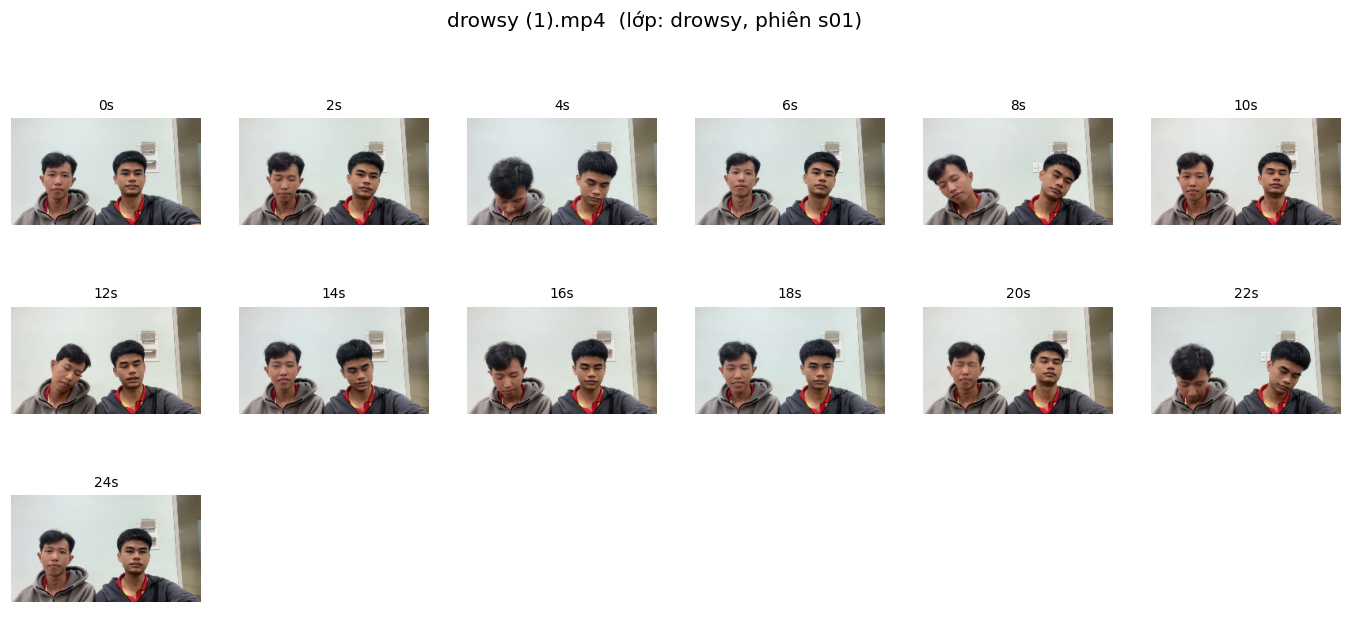

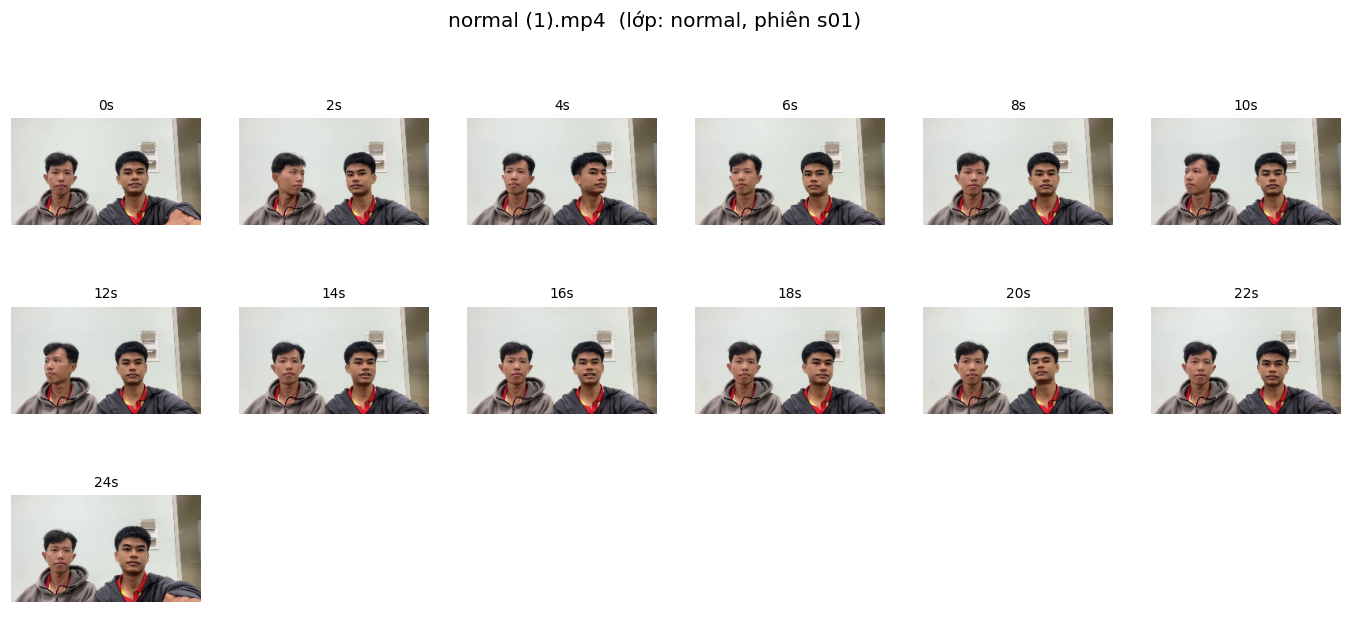

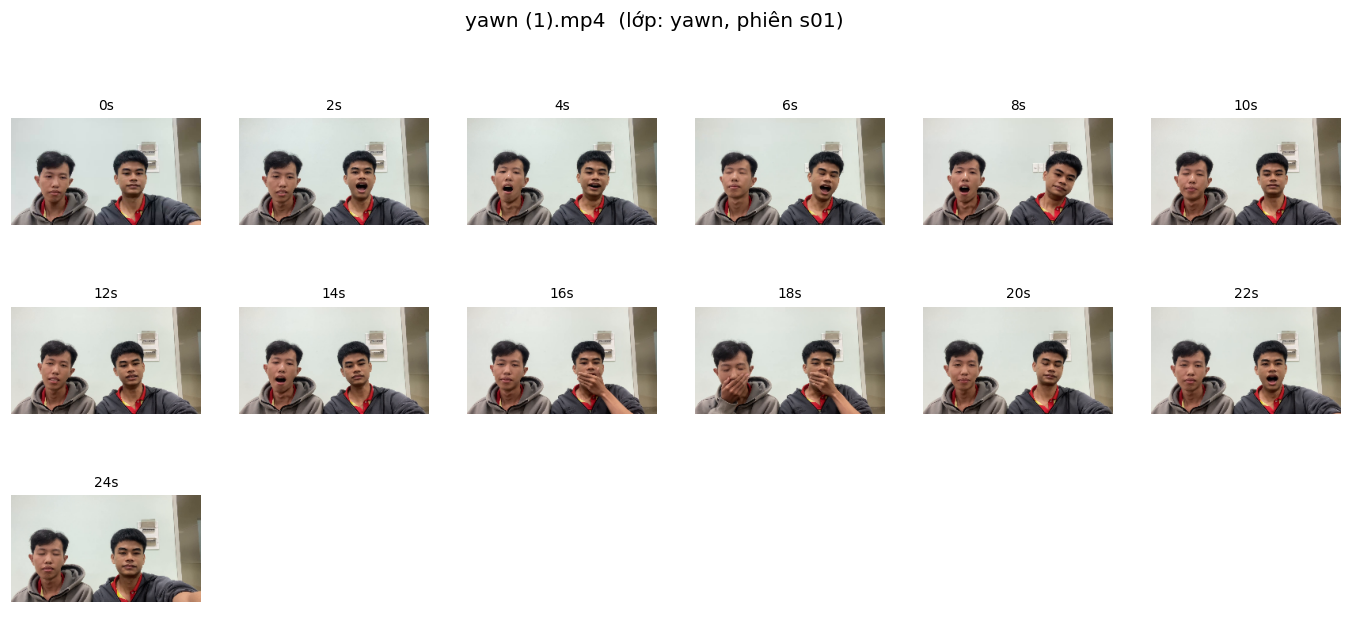

In [ ]:
# 1.3 Ảnh xem nhanh theo thời gian của từng video: dùng để chọn đoạn cần giữ (CLIP_KEEP) ở ô sau
def contact_sheet(v, step_s=2.0, max_thumbs=24):
    cap = cv2.VideoCapture(str(v['path']))
    step = max(1, int(round(v['fps'] * step_s)))
    thumbs, i = [], 0
    while len(thumbs) < max_thumbs:
        if not cap.grab():
            break
        if i % step == 0:
            ok, fr = cap.retrieve()
            if ok:
                thumbs.append((i / v['fps'], cv2.resize(fr, (240, int(240 * fr.shape[0] / fr.shape[1])))))
        i += 1
    cap.release()
    return thumbs

for v in vid_info:
    th = contact_sheet(v)
    cols = 6
    rows_n = max(1, math.ceil(len(th) / cols))
    fig, axes = plt.subplots(rows_n, cols, figsize=(2.6 * cols, 2.1 * rows_n))
    for ax in np.atleast_1d(axes).ravel():
        ax.axis('off')
    for ax, (t, im) in zip(np.atleast_1d(axes).ravel(), th):
        ax.imshow(im[..., ::-1]); ax.set_title(f'{t:.0f}s', fontsize=9)
    fig.suptitle(f"{v['path'].name}  (lớp: {v['label']}, phiên {v['session']})", y=1.0)
    plt.show()

In [ ]:
# 1.4 Tách khung hình cách quãng. Mỗi khung mang nhãn của video chứa nó.
TARGET_PER_CLASS = 500      # số ảnh mong muốn cho mỗi lớp (chia đều cho các video của lớp đó)
TRIM_EDGE_S = 1.0           # cắt bỏ 1 giây đầu và cuối mỗi video (lúc bấm quay, chỉnh tư thế)
MAX_SIDE = 1280             # thu nhỏ nếu cạnh dài hơn giá trị này
REBUILD = True              # True: xóa ảnh/nhãn cũ trong raw/ trước khi tạo mới

# Muốn nhãn SẠCH HƠN: chỉ giữ các đoạn thể hiện rõ trạng thái (giây). Ví dụ:
#   CLIP_KEEP = {'yawn.mp4': [(3, 6), (11, 15)], 'drowsy.mp4': [(8, 40)]}
# Xem ảnh xem nhanh ở ô 1.3 để chọn. Video không có trong dict thì giữ toàn bộ (trừ phần đầu/cuối).
CLIP_KEEP = {}

if REBUILD:
    for d in (RAW_IMAGES, RAW_LABELS):
        for p in d.glob('*'):
            p.unlink()

n_vid_of_class = Counter(v['label'] for v in vid_info)
meta_rows = []
for k, v in enumerate(vid_info):
    name = v['path'].name
    intervals = CLIP_KEEP.get(name, [(TRIM_EDGE_S, max(TRIM_EDGE_S + 1, v['duration'] - TRIM_EDGE_S))])
    valid_frames = sum(max(0.0, min(b, v['duration']) - a) for a, b in intervals) * v['fps']
    target = max(10, math.ceil(TARGET_PER_CLASS / n_vid_of_class[v['label']]))
    stride = max(1, int(round(valid_frames / target)))
    cap = cv2.VideoCapture(str(v['path']))
    i = valid_i = saved = 0
    while True:
        ok, frame = cap.read()
        if not ok:
            break
        t = i / v['fps']
        i += 1
        if not any(a <= t < b for a, b in intervals):
            continue
        valid_i += 1
        if (valid_i - 1) % stride != 0:
            continue
        sc = MAX_SIDE / max(frame.shape[:2])
        if sc < 1:
            frame = cv2.resize(frame, None, fx=sc, fy=sc, interpolation=cv2.INTER_AREA)
        img_name = f"{v['session']}_{v['label']}_{k:02d}_{saved:05d}.jpg"
        cv2.imwrite(str(RAW_IMAGES / img_name), frame, [cv2.IMWRITE_JPEG_QUALITY, 92])
        meta_rows.append(dict(image=img_name, video=name, session=v['session'], label=v['label'], t_sec=round(t, 3), samp_fps=v['fps'] / stride))
        saved += 1
    cap.release()
    print(f'{name}: lấy {saved} ảnh (cách {stride} khung, tương đương {v["fps"] / stride:.1f} ảnh/giây)')

frames_meta = pd.DataFrame(meta_rows)
frames_meta.to_csv(ROOT / 'raw' / 'frames_meta.csv', index=False)
display(frames_meta.groupby(['session', 'label']).size().unstack(fill_value=0))

drowsy (1).mp4: lấy 703 ảnh (cách 1 khung, tương đương 30.0 ảnh/giây)
normal (1).mp4: lấy 673 ảnh (cách 1 khung, tương đương 30.0 ảnh/giây)
yawn (1).mp4: lấy 696 ảnh (cách 1 khung, tương đương 30.0 ảnh/giây)


label,drowsy,normal,yawn
session,,,
s01,703,673,696


In [ ]:
# 1.5 Dò khuôn mặt tự động và tạo nhãn YOLO
# Chuỗi xử lý: (a) bộ dò khuôn mặt SSD của OpenCV  →  (b) nội suy theo thời gian cho khung bị lỡ (video liên tục nên hộp đổi từ từ)
#              →  (c) bộ dò người COCO (YOLOv8n) lấy phần đầu cho khung còn lại (ví dụ cúi đầu)  →  (d) làm mượt hộp bằng trung vị  →  (e) bỏ khung vẫn không có hộp
USE_PERSON_FALLBACK = True
MAX_INTERP_GAP = 12         # chỉ nội suy khi khoảng trống tối đa 12 ảnh liên tiếp

def load_face_net():
    import urllib.request
    d = ROOT / 'models_aux'
    d.mkdir(exist_ok=True)
    files_needed = {
        d / 'deploy.prototxt': 'https://raw.githubusercontent.com/opencv/opencv/master/samples/dnn/face_detector/deploy.prototxt',
        d / 'res10_300x300_ssd_iter_140000.caffemodel': 'https://raw.githubusercontent.com/opencv/opencv_3rdparty/dnn_samples_face_detector_20170830/res10_300x300_ssd_iter_140000.caffemodel',
    }
    try:
        for path, url in files_needed.items():
            if not path.exists() or path.stat().st_size < 1000:
                urllib.request.urlretrieve(url, str(path))
        return cv2.dnn.readNetFromCaffe(str(d / 'deploy.prototxt'), str(d / 'res10_300x300_ssd_iter_140000.caffemodel'))
    except Exception as e:
        print('Không tải được bộ dò SSD, dùng Haar cascade thay thế:', e)
        return None

face_net = load_face_net()
haar = cv2.CascadeClassifier(cv2.data.haarcascades + 'haarcascade_frontalface_default.xml')

def detect_face(img, thr=0.5):
    """Trả về hộp khuôn mặt lớn nhất (x1,y1,x2,y2) theo pixel, hoặc None."""
    H, W = img.shape[:2]
    if face_net is not None:
        blob = cv2.dnn.blobFromImage(cv2.resize(img, (300, 300)), 1.0, (300, 300), (104.0, 177.0, 123.0))
        face_net.setInput(blob)
        det = face_net.forward()[0, 0]
        cands = [(d[3] * W, d[4] * H, d[5] * W, d[6] * H) for d in det if d[2] >= thr]
        if cands:
            return max(cands, key=lambda b: (b[2] - b[0]) * (b[3] - b[1]))
        return None
    faces = haar.detectMultiScale(cv2.cvtColor(img, cv2.COLOR_BGR2GRAY), 1.1, 5, minSize=(60, 60))
    if len(faces) == 0:
        return None
    x, y, w, h = max(faces, key=lambda f: f[2] * f[3])
    return (x, y, x + w, y + h)

def expand_head_box(b, W, H, ew=1.35, eh=1.55):
    """Hộp khuôn mặt → hộp phủ cả đầu (giống cách gán nhãn: ôm cả mặt và phần đầu)."""
    cx, cy, w, h = (b[0] + b[2]) / 2, (b[1] + b[3]) / 2 - 0.06 * (b[3] - b[1]), (b[2] - b[0]) * ew, (b[3] - b[1]) * eh
    return (max(0, cx - w / 2), max(0, cy - h / 2), min(W, cx + w / 2), min(H, cy + h / 2))

coco_model = None
def person_head_box(img):
    global coco_model
    if coco_model is None:
        coco_model = YOLO('yolov8n.pt')
    r = coco_model.predict(img, classes=[0], conf=0.3, imgsz=640, device=DEVICE, verbose=False)[0]
    if len(r.boxes) == 0:
        return None
    x1, y1, x2, y2 = max(r.boxes.xyxy.cpu().numpy(), key=lambda b: (b[2] - b[0]) * (b[3] - b[1]))
    pw, ph = x2 - x1, y2 - y1
    hw = min(pw * 0.65, ph * 0.9)
    hh = min(ph * 0.6, hw * 1.3)
    cx = (x1 + x2) / 2
    return (cx - hw / 2, y1, cx + hw / 2, y1 + hh)

def iou_box(a, b):
    ix1, iy1, ix2, iy2 = max(a[0], b[0]), max(a[1], b[1]), min(a[2], b[2]), min(a[3], b[3])
    inter = max(0, ix2 - ix1) * max(0, iy2 - iy1)
    union = (a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter
    return inter / union if union > 0 else 0

def fill_gaps(boxes, max_gap=MAX_INTERP_GAP):
    out, src = list(boxes), ['face' if b is not None else None for b in boxes]
    idx = [i for i, b in enumerate(boxes) if b is not None]
    for i, b in enumerate(boxes):
        if b is not None:
            continue
        prev = max((j for j in idx if j < i), default=None)
        nxt = min((j for j in idx if j > i), default=None)
        if prev is not None and nxt is not None and nxt - prev <= max_gap:
            a = (i - prev) / (nxt - prev)
            out[i] = tuple((1 - a) * p + a * q for p, q in zip(boxes[prev], boxes[nxt]))
            src[i] = 'interp'
        elif prev is not None and i - prev <= 3:
            out[i], src[i] = boxes[prev], 'hold'
        elif nxt is not None and nxt - i <= 3:
            out[i], src[i] = boxes[nxt], 'hold'
    return out, src

# --- Kiểm tra độ tin cậy của phương án dự phòng "đầu từ khung người": so với hộp khuôn mặt ở các khung dò được
if USE_PERSON_FALLBACK:
    probe_names = frames_meta.sample(min(60, len(frames_meta)), random_state=SEED).image.tolist()
    ious = []
    for n in probe_names:
        im = cv2.imread(str(RAW_IMAGES / n))
        fb, pb = detect_face(im), person_head_box(im)
        if fb is not None and pb is not None:
            ious.append(iou_box(expand_head_box(fb, im.shape[1], im.shape[0]), pb))
    if ious:
        print(f'IoU trung bình giữa hộp "đầu từ khung người" và hộp khuôn mặt: {np.mean(ious):.2f} (trên {len(ious)} ảnh)')
        if np.mean(ious) < 0.4:
            USE_PERSON_FALLBACK = False
            print('→ Quá thấp, TẮT phương án dự phòng này để tránh nhãn sai. Khung không dò được mặt sẽ bị bỏ.')

# --- Gán nhãn từng video
label_stats = []
final_src = {}
for vname, g in frames_meta.groupby('video', sort=False):
    g = g.sort_values('t_sec')
    names = g.image.tolist()
    cls_id = CLASS_NAMES.index(g.label.iloc[0])
    imgs = [cv2.imread(str(RAW_IMAGES / n)) for n in names]
    H, W = imgs[0].shape[:2]
    raw_boxes = []
    for im in imgs:
        fb = detect_face(im)
        raw_boxes.append(expand_head_box(fb, W, H) if fb is not None else None)
    boxes, src = fill_gaps(raw_boxes)
    if USE_PERSON_FALLBACK:
        for i, b in enumerate(boxes):
            if b is None:
                pb = person_head_box(imgs[i])
                if pb is not None:
                    boxes[i], src[i] = (max(0, pb[0]), max(0, pb[1]), min(W, pb[2]), min(H, pb[3])), 'person'
    # làm mượt bằng trung vị trượt (cửa sổ 5) trên các khung có hộp
    have = [i for i, b in enumerate(boxes) if b is not None]
    if have:
        arr = pd.DataFrame([boxes[i] for i in have], index=have).rolling(5, center=True, min_periods=1).median()
        for i in have:
            boxes[i] = tuple(arr.loc[i].values)
    n_written = 0
    for n, b, s in zip(names, boxes, src):
        if b is None:
            (RAW_IMAGES / n).unlink()
            continue
        bw, bh = (b[2] - b[0]) / W, (b[3] - b[1]) / H
        if not (0.08 <= bw <= 1.0 and 0.08 <= bh <= 1.0):
            (RAW_IMAGES / n).unlink()
            src[names.index(n)] = None
            continue
        cx, cy = (b[0] + b[2]) / 2 / W, (b[1] + b[3]) / 2 / H
        (RAW_LABELS / f'{Path(n).stem}.txt').write_text(f'{cls_id} {cx:.6f} {cy:.6f} {bw:.6f} {bh:.6f}\n')
        final_src[n] = s
        n_written += 1
    c = Counter(src)
    label_stats.append({'Video': vname, 'Tổng ảnh': len(names), 'Dò được mặt': c['face'], 'Nội suy': c['interp'] + c['hold'],
                        'Từ khung người': c['person'], 'Bỏ (không có hộp)': len(names) - n_written})
    print(f'{vname}: đã gán nhãn {n_written}/{len(names)} ảnh')

label_stats = pd.DataFrame(label_stats).set_index('Video')
display(label_stats)
save_table(label_stats, 'bang_gan_nhan_tu_dong')
frames_meta = frames_meta[frames_meta.image.isin(final_src)].copy()
frames_meta['source'] = frames_meta.image.map(final_src)
frames_meta.to_csv(ROOT / 'raw' / 'frames_meta.csv', index=False)
print('Số ảnh còn lại sau gán nhãn:', len(frames_meta))
share_bad = 1 - (frames_meta.source == 'face').mean()
print(f'Tỷ lệ hộp không đến trực tiếp từ bộ dò mặt: {share_bad:.0%} (với video drowsy cúi đầu nhiều, mức 20–50% là bình thường).')

IoU trung bình giữa hộp "đầu từ khung người" và hộp khuôn mặt: 0.14 (trên 60 ảnh)
→ Quá thấp, TẮT phương án dự phòng này để tránh nhãn sai. Khung không dò được mặt sẽ bị bỏ.
drowsy (1).mp4: đã gán nhãn 703/703 ảnh
normal (1).mp4: đã gán nhãn 673/673 ảnh
yawn (1).mp4: đã gán nhãn 696/696 ảnh


,Tổng ảnh,Dò được mặt,Nội suy,Từ khung người,Bỏ (không có hộp)
Video,,,,,
drowsy (1).mp4,703,703,0,0,0
normal (1).mp4,673,673,0,0,0
yawn (1).mp4,696,696,0,0,0


Đã lưu bảng: /content/drive/MyDrive/drowsiness_yolov8/report_assets/bang_gan_nhan_tu_dong.csv
Số ảnh còn lại sau gán nhãn: 2072
Tỷ lệ hộp không đến trực tiếp từ bộ dò mặt: 0% (với video drowsy cúi đầu nhiều, mức 20–50% là bình thường).


Đã lưu hình: /content/drive/MyDrive/drowsiness_yolov8/report_assets/hinh_2_0_kiem_tra_nhan_tu_dong.png


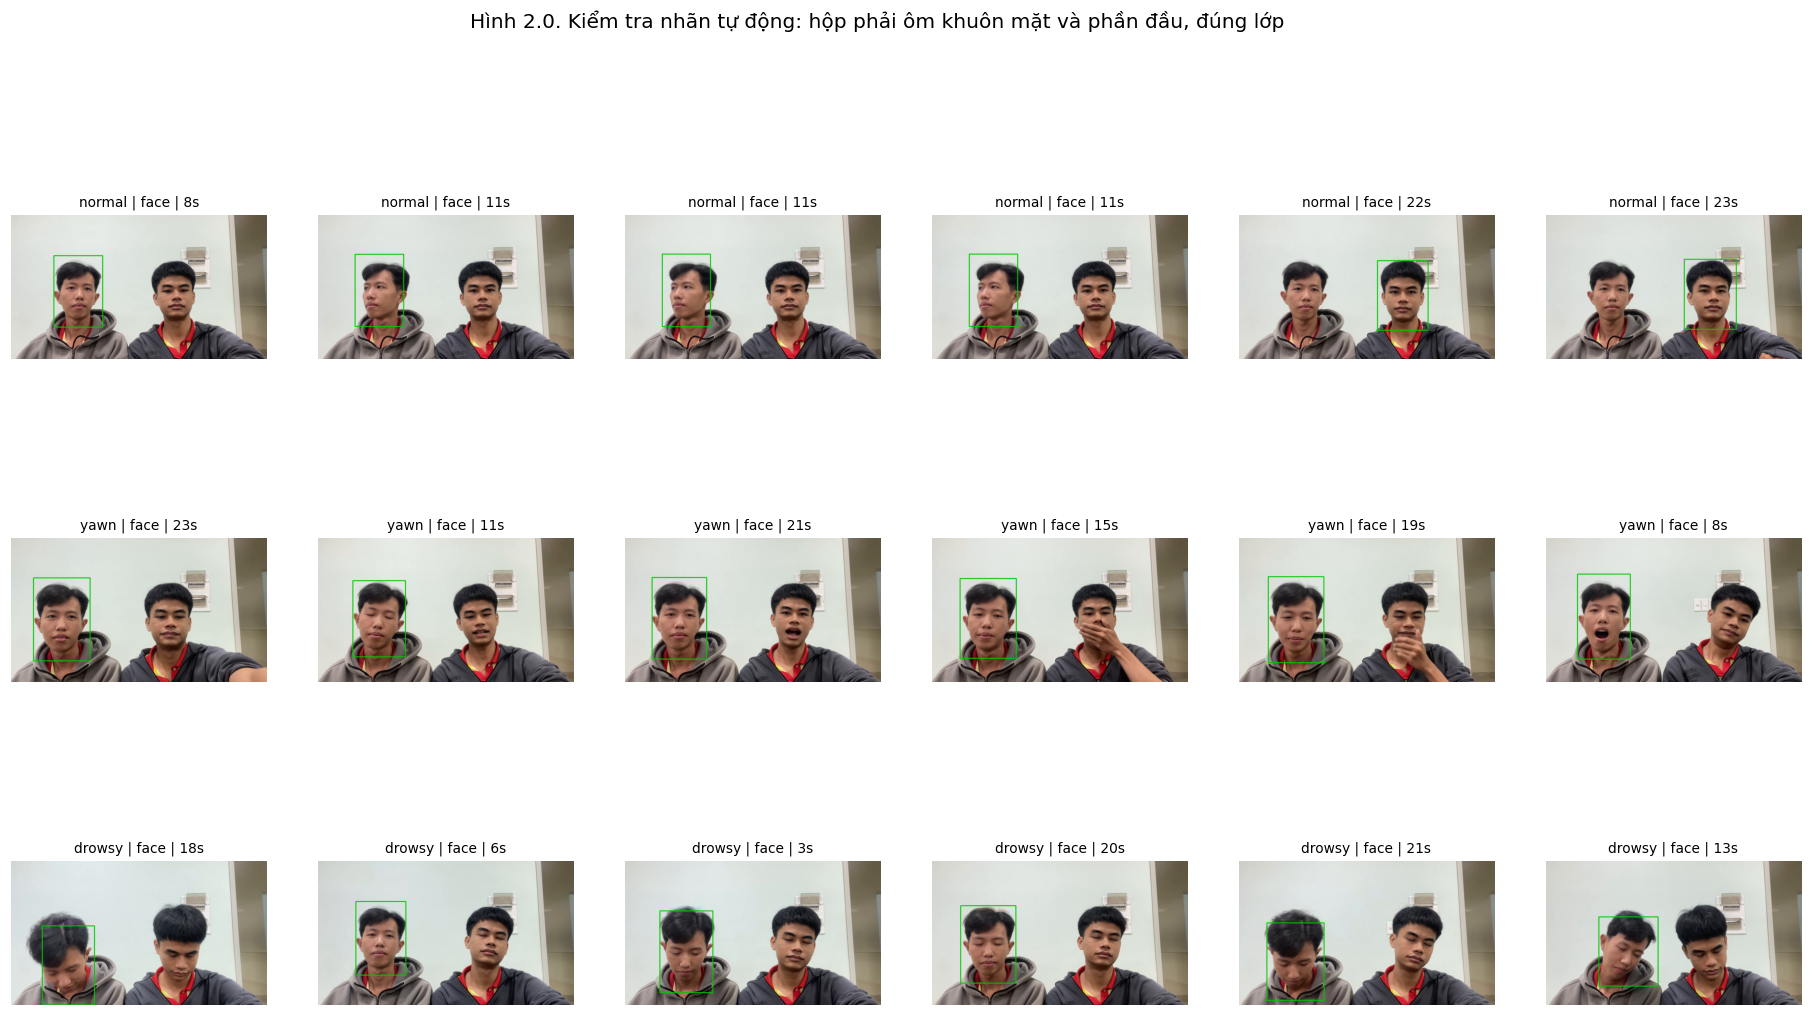

Nếu thấy nhiều hộp lệch (nhất là màu cam/xanh dương ở video drowsy): 
 - đặt USE_PERSON_FALLBACK = False rồi chạy lại ô 1.4–1.6 (khung không dò được mặt sẽ bị bỏ, nhãn sạch hơn),
 - hoặc dùng CLIP_KEEP ở ô 1.4 để chỉ giữ đoạn cúi đầu mà mặt vẫn còn thấy rõ,
 - hoặc xuất ảnh sang Make Sense để chỉnh tay (https://www.makesense.ai).


In [ ]:
# 1.6 KIỂM TRA BẰNG MẮT: màu khung cho biết nguồn nhãn (xanh lá = dò trực tiếp, xanh dương = nội suy, vàng = giữ khung gần nhất, cam = từ khung người)
SRC_BGR = {'face': (0, 200, 0), 'interp': (255, 120, 0), 'hold': (255, 200, 0), 'person': (0, 140, 255)}
fig, axes = plt.subplots(NC, 6, figsize=(21, 3.6 * NC))
for r, cname in enumerate(CLASS_NAMES):
    sub = frames_meta[frames_meta.label == cname]
    pick = sub.sample(min(6, len(sub)), random_state=SEED) if len(sub) else sub
    for ax in axes[r]:
        ax.axis('off')
    for ax, (_, row) in zip(axes[r], pick.iterrows()):
        im = cv2.imread(str(RAW_IMAGES / row.image))
        H, W = im.shape[:2]
        _, cx, cy, bw, bh = map(float, (RAW_LABELS / f'{Path(row.image).stem}.txt').read_text().split())
        p1, p2 = (int((cx - bw / 2) * W), int((cy - bh / 2) * H)), (int((cx + bw / 2) * W), int((cy + bh / 2) * H))
        cv2.rectangle(im, p1, p2, SRC_BGR.get(row.source, (255, 255, 255)), max(3, W // 300))
        ax.imshow(im[..., ::-1]); ax.set_title(f'{cname} | {row.source} | {row.t_sec:.0f}s', fontsize=9)
fig.suptitle('Hình 2.0. Kiểm tra nhãn tự động: hộp phải ôm khuôn mặt và phần đầu, đúng lớp', y=1.0)
save_fig(fig, 'hinh_2_0_kiem_tra_nhan_tu_dong')
print('Nếu thấy nhiều hộp lệch (nhất là màu cam/xanh dương ở video drowsy): ')
print(' - đặt USE_PERSON_FALLBACK = False rồi chạy lại ô 1.4–1.6 (khung không dò được mặt sẽ bị bỏ, nhãn sạch hơn),')
print(' - hoặc dùng CLIP_KEEP ở ô 1.4 để chỉ giữ đoạn cúi đầu mà mặt vẫn còn thấy rõ,')
print(' - hoặc xuất ảnh sang Make Sense để chỉnh tay (https://www.makesense.ai).')

## Phần 2. Kiểm tra nhãn, thống kê dữ liệu, histogram độ sáng (mục 2.4 – 2.5)

In [ ]:
# 2.1 Kiểm tra tính hợp lệ của ảnh và nhãn
IMG_EXT = {'.jpg', '.jpeg', '.png', '.bmp'}
images = sorted(p for p in RAW_IMAGES.iterdir() if p.suffix.lower() in IMG_EXT)
label_files = {p.stem: p for p in RAW_LABELS.glob('*.txt')}
assert len(images) > 0, f'Không thấy ảnh trong {RAW_IMAGES}. Hãy làm Phần 1 trước.'

rows, problems = [], []
for p in images:
    lp = label_files.get(p.stem)
    if lp is None:
        problems.append((p.name, 'thiếu tệp nhãn'))
        continue
    lines = [l.split() for l in lp.read_text().strip().splitlines() if l.strip()]
    if not lines:
        problems.append((p.name, 'tệp nhãn rỗng'))
        continue
    for parts in lines:
        if len(parts) != 5:
            problems.append((p.name, f'dòng nhãn sai định dạng: {parts}'))
            continue
        try:
            c = int(parts[0])
            xc, yc, w, h = map(float, parts[1:])
        except ValueError:
            problems.append((p.name, f'giá trị không phải số: {parts}'))
            continue
        if not 0 <= c < NC:
            problems.append((p.name, f'class_id {c} ngoài khoảng 0..{NC - 1}'))
            continue
        if not all(0 <= v <= 1 for v in (xc, yc, w, h)) or w <= 0 or h <= 0:
            problems.append((p.name, f'tọa độ ngoài [0,1] hoặc kích thước <= 0: {parts}'))
            continue
        rows.append(dict(image=p.name, stem=p.stem, cls=c, xc=xc, yc=yc, w=w, h=h))

labels_df = pd.DataFrame(rows)
orphans = sorted(set(label_files) - {p.stem for p in images})

# Đối chiếu class_id với lớp ghi trong tên tệp (nếu tên theo quy ước s01_normal_0001.jpg)
mismatch = []
for r in rows:
    named = next((i for i, n in enumerate(CLASS_NAMES) if f'_{n}_' in r['stem']), None)
    if named is not None and named != r['cls']:
        mismatch.append(r['image'])

print(f'Số ảnh: {len(images)} | số tệp nhãn: {len(label_files)} | số hộp hợp lệ: {len(labels_df)}')
print(f'Vấn đề phát hiện: {len(problems)} | nhãn không có ảnh: {len(orphans)} | lệch lớp so với tên tệp: {len(set(mismatch))}')
if problems:
    display(pd.DataFrame(problems, columns=['Ảnh', 'Vấn đề']).head(30))
if mismatch:
    print('⚠️ Ví dụ ảnh có class_id khác lớp trong tên tệp (kiểm tra thứ tự CLASS_NAMES):', sorted(set(mismatch))[:5])
labels_df = labels_df[~labels_df.image.isin({p[0] for p in problems})].reset_index(drop=True)

Số ảnh: 2072 | số tệp nhãn: 2072 | số hộp hợp lệ: 2072
Vấn đề phát hiện: 0 | nhãn không có ảnh: 0 | lệch lớp so với tên tệp: 0


Đã lưu hình: /content/drive/MyDrive/drowsiness_yolov8/report_assets/hinh_2_0_kiem_tra_nhan.png


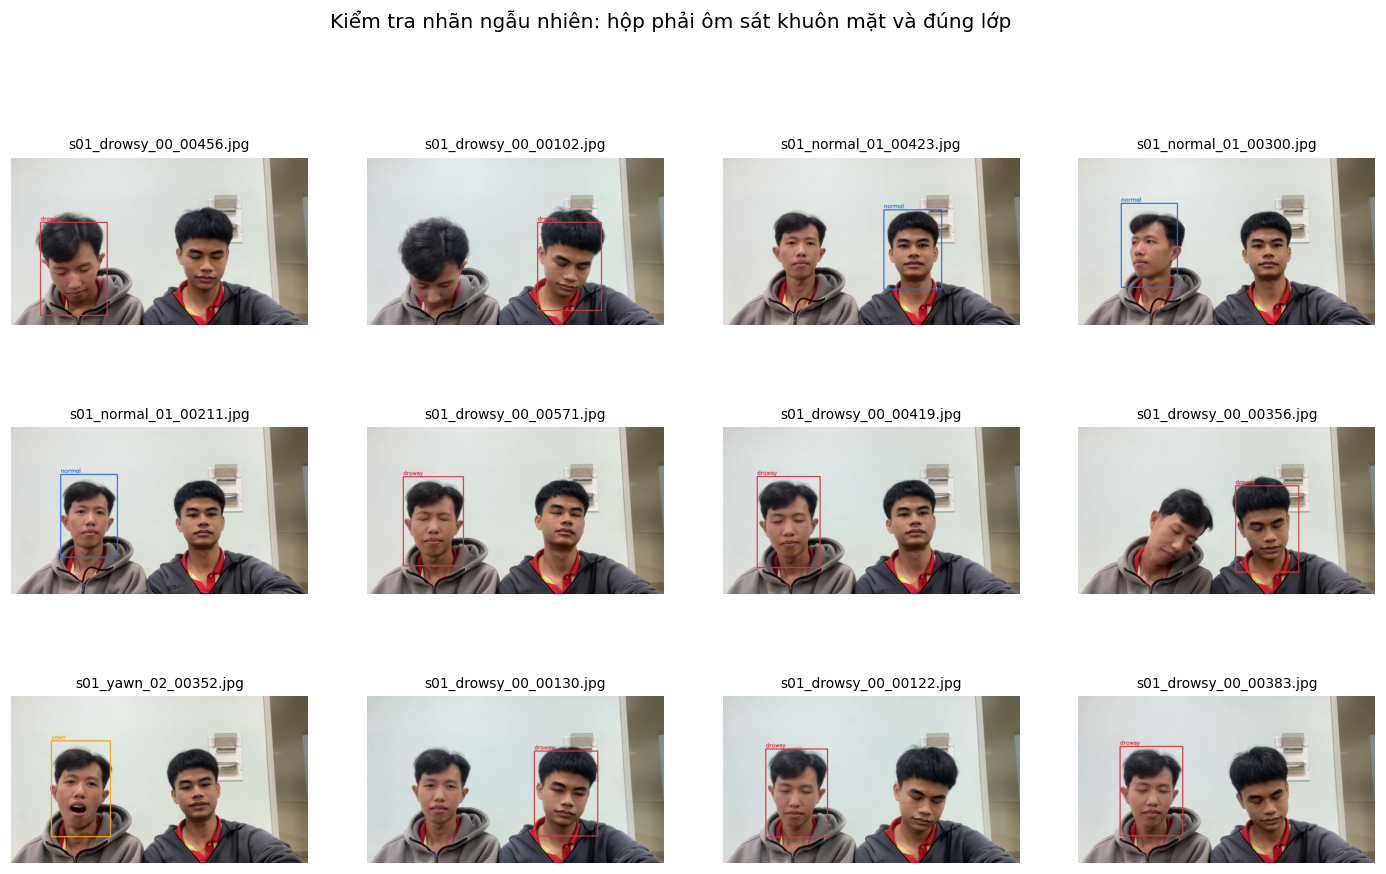

In [ ]:
# 2.2 Xem ngẫu nhiên 12 ảnh kèm hộp nhãn để kiểm tra bằng mắt
def draw_gt(img, sub):
    H, W = img.shape[:2]
    for _, r in sub.iterrows():
        x1, y1 = int((r.xc - r.w / 2) * W), int((r.yc - r.h / 2) * H)
        x2, y2 = int((r.xc + r.w / 2) * W), int((r.yc + r.h / 2) * H)
        name = CLASS_NAMES[int(r.cls)]
        col = tuple(int(CLASS_COLORS[name][i:i + 2], 16) for i in (5, 3, 1))   # hex -> BGR
        cv2.rectangle(img, (x1, y1), (x2, y2), col, max(2, W // 400))
        cv2.putText(img, name, (x1, max(20, y1 - 8)), cv2.FONT_HERSHEY_SIMPLEX, max(0.6, W / 1600), col, 2)
    return img

sample_imgs = random.Random(SEED).sample(sorted(labels_df.image.unique()), min(12, labels_df.image.nunique()))
fig, axes = plt.subplots(3, 4, figsize=(16, 9))
for ax, name in zip(axes.ravel(), sample_imgs):
    img = cv2.imread(str(RAW_IMAGES / name))
    img = draw_gt(img, labels_df[labels_df.image == name])
    ax.imshow(img[..., ::-1])
    ax.set_title(name, fontsize=9)
    ax.axis('off')
fig.suptitle('Kiểm tra nhãn ngẫu nhiên: hộp phải ôm sát khuôn mặt và đúng lớp', y=1.0)
save_fig(fig, 'hinh_2_0_kiem_tra_nhan')

Tổng ảnh: 2072 | số phiên/khối: 1 | độ phân giải ảnh đầu tiên: 1280x720


,Số ảnh,Số hộp,Rộng TB (chuẩn hóa),Cao TB (chuẩn hóa)
normal,673.0,673.0,0.191,0.487
yawn,696.0,696.0,0.213,0.568
drowsy,703.0,703.0,0.213,0.528
Tổng,2072.0,2072.0,NaN,NaN


Đã lưu bảng: /content/drive/MyDrive/drowsiness_yolov8/report_assets/bang_2_1_thong_ke_du_lieu.csv
Đã lưu bảng: /content/drive/MyDrive/drowsiness_yolov8/report_assets/thong_ke_tung_anh.csv
Đã lưu hình: /content/drive/MyDrive/drowsiness_yolov8/report_assets/bieu_do_2_1_phan_bo_lop.png


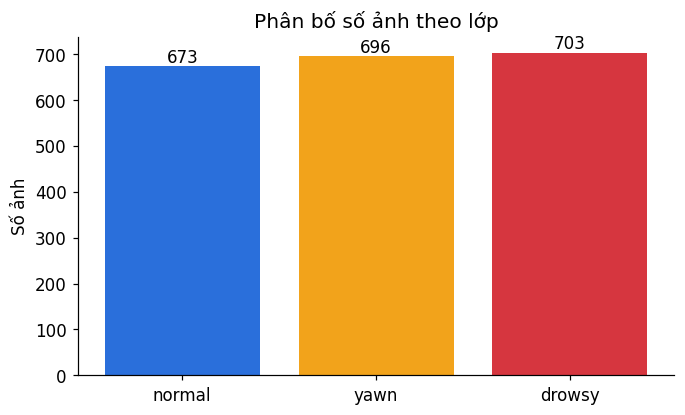

Đã lưu hình: /content/drive/MyDrive/drowsiness_yolov8/report_assets/bieu_do_2_2_vi_tri_kich_thuoc_hop.png


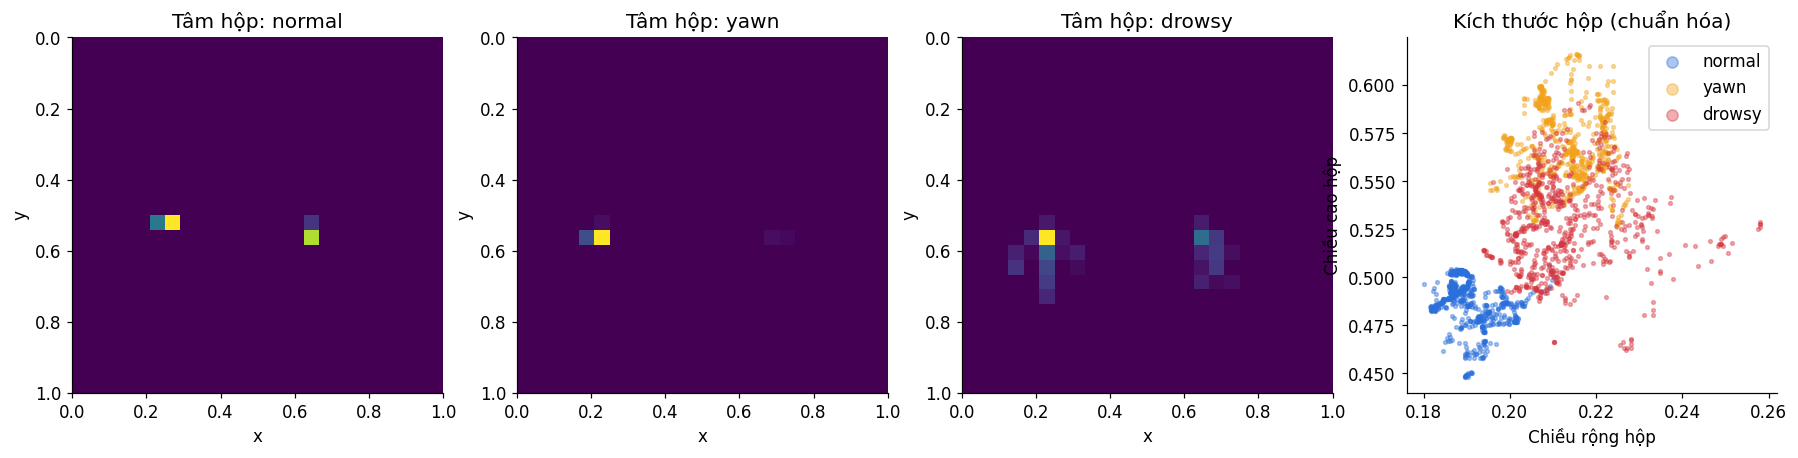

In [ ]:
# 2.3 Thống kê bộ dữ liệu: số ảnh theo lớp, kích thước hộp, độ sáng từng ảnh, phiên chụp
def session_of(name):
    stem = Path(name).stem
    m = re.match(r'^(s\d+)_', stem)
    if m:
        return m.group(1)
    m = re.search(r'(\d+)$', stem)
    if m:
        return f'block{int(m.group(1)) // BLOCK_SIZE:03d}'
    return 'unknown'

def image_stats(name):
    img = cv2.imread(str(RAW_IMAGES / name))
    small = cv2.resize(img, (160, max(1, int(160 * img.shape[0] / img.shape[1]))))
    v = cv2.cvtColor(small, cv2.COLOR_BGR2HSV)[..., 2]
    g = cv2.cvtColor(small, cv2.COLOR_BGR2GRAY)
    return float(v.mean()), float(g.std())

img_df = (labels_df.groupby('image')['cls'].agg(lambda s: int(s.mode().iloc[0])).reset_index())
with ThreadPoolExecutor(8) as ex:
    stats = list(ex.map(image_stats, img_df.image))
img_df['brightness'] = [s[0] for s in stats]
img_df['contrast'] = [s[1] for s in stats]
img_df['session'] = img_df.image.map(session_of)
META_PATH = ROOT / 'raw' / 'frames_meta.csv'
if META_PATH.exists():          # dữ liệu tạo từ video ở Phần 1: có mốc thời gian từng khung
    _meta = pd.read_csv(META_PATH).drop_duplicates('image').set_index('image')
    img_df = img_df.join(_meta[['video', 't_sec', 'samp_fps', 'source']], on='image')
img_df['class_name'] = img_df.cls.map(dict(enumerate(CLASS_NAMES)))
img_df = img_df.set_index('image', drop=False)

summary = pd.DataFrame({
    'Số ảnh': img_df.groupby('class_name').size(),
    'Số hộp': labels_df.assign(c=labels_df.cls.map(dict(enumerate(CLASS_NAMES)))).groupby('c').size(),
    'Rộng TB (chuẩn hóa)': labels_df.assign(c=labels_df.cls.map(dict(enumerate(CLASS_NAMES)))).groupby('c').w.mean().round(3),
    'Cao TB (chuẩn hóa)': labels_df.assign(c=labels_df.cls.map(dict(enumerate(CLASS_NAMES)))).groupby('c').h.mean().round(3),
}).reindex(CLASS_NAMES)
summary.loc['Tổng'] = [summary['Số ảnh'].sum(), summary['Số hộp'].sum(), np.nan, np.nan]
print(f"Tổng ảnh: {len(img_df)} | số phiên/khối: {img_df.session.nunique()} | độ phân giải ảnh đầu tiên: {cv2.imread(str(RAW_IMAGES / img_df.image.iloc[0])).shape[1]}x{cv2.imread(str(RAW_IMAGES / img_df.image.iloc[0])).shape[0]}")
display(summary)
save_table(summary, 'bang_2_1_thong_ke_du_lieu')
save_table(img_df.drop(columns=['image']), 'thong_ke_tung_anh')
RESULTS['dataset_summary'] = summary

# Biểu đồ 2.1: số ảnh theo lớp
fig, ax = plt.subplots(figsize=(7, 4))
counts = img_df.class_name.value_counts().reindex(CLASS_NAMES)
bars = ax.bar(counts.index, counts.values, color=[CLASS_COLORS[c] for c in counts.index])
for b, v in zip(bars, counts.values):
    ax.text(b.get_x() + b.get_width() / 2, v, str(v), ha='center', va='bottom')
ax.set_ylabel('Số ảnh')
ax.set_title('Phân bố số ảnh theo lớp')
save_fig(fig, 'bieu_do_2_1_phan_bo_lop')

# Biểu đồ 2.2: phân bố vị trí tâm hộp (heatmap) và kích thước hộp
fig, axes = plt.subplots(1, NC + 1, figsize=(5 * (NC + 1), 4.2))
for ax, (i, name) in zip(axes, enumerate(CLASS_NAMES)):
    sub = labels_df[labels_df.cls == i]
    h = ax.hist2d(sub.xc, sub.yc, bins=24, range=[[0, 1], [0, 1]], cmap='viridis')
    ax.invert_yaxis()
    ax.set_title(f'Tâm hộp: {name}')
    ax.set_xlabel('x'); ax.set_ylabel('y')
for i, name in enumerate(CLASS_NAMES):
    sub = labels_df[labels_df.cls == i]
    axes[-1].scatter(sub.w, sub.h, s=6, alpha=0.4, color=CLASS_COLORS[name], label=name)
axes[-1].set_xlabel('Chiều rộng hộp'); axes[-1].set_ylabel('Chiều cao hộp')
axes[-1].set_title('Kích thước hộp (chuẩn hóa)')
axes[-1].legend(markerscale=3)
save_fig(fig, 'bieu_do_2_2_vi_tri_kich_thuoc_hop')

Đã lưu hình: /content/drive/MyDrive/drowsiness_yolov8/report_assets/bieu_do_2_3_histogram_do_sang.png


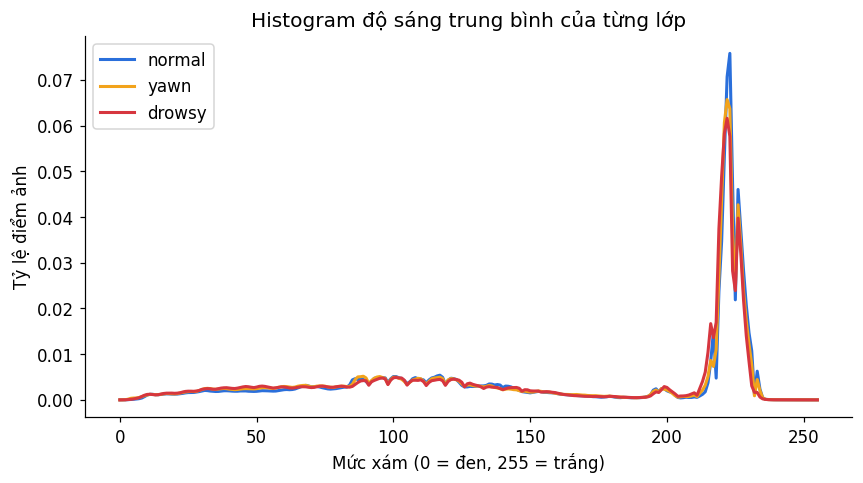

,Độ sáng TB,Độ lệch chuẩn,% ảnh tối (V<60),% ảnh cháy sáng (V>200)
class_name,,,,
normal,175.2,0.6,0.0,0.0
yawn,171.3,1.1,0.0,0.0
drowsy,171.0,2.1,0.0,0.0


Đã lưu bảng: /content/drive/MyDrive/drowsiness_yolov8/report_assets/bang_2_2_do_sang_theo_lop.csv


In [ ]:
# 2.4 Phân tích histogram độ sáng theo lớp (Biểu đồ 2.3 + Bảng độ sáng)
def gray_hist(name):
    g = cv2.imread(str(RAW_IMAGES / name), cv2.IMREAD_GRAYSCALE)
    g = cv2.resize(g, (320, max(1, int(320 * g.shape[0] / g.shape[1]))))
    h = cv2.calcHist([g], [0], None, [256], [0, 256]).ravel()
    return h / h.sum()

fig, ax = plt.subplots(figsize=(9, 4.5))
for name in CLASS_NAMES:
    names = img_df[img_df.class_name == name].image.tolist()
    names = random.Random(SEED).sample(names, min(300, len(names)))
    mean_h = np.mean([gray_hist(n) for n in names], axis=0)
    ax.plot(mean_h, color=CLASS_COLORS[name], lw=2, label=name)
ax.set_xlabel('Mức xám (0 = đen, 255 = trắng)')
ax.set_ylabel('Tỷ lệ điểm ảnh')
ax.set_title('Histogram độ sáng trung bình của từng lớp')
ax.legend()
save_fig(fig, 'bieu_do_2_3_histogram_do_sang')

bright_tbl = img_df.groupby('class_name').agg(
    do_sang_tb=('brightness', 'mean'),
    do_lech_chuan=('brightness', 'std'),
    pct_toi=('brightness', lambda s: 100 * (s < DARK_T).mean()),
    pct_chay_sang=('brightness', lambda s: 100 * (s > 200).mean()),
).reindex(CLASS_NAMES).round(1)
bright_tbl.columns = ['Độ sáng TB', 'Độ lệch chuẩn', f'% ảnh tối (V<{DARK_T})', '% ảnh cháy sáng (V>200)']
display(bright_tbl)
save_table(bright_tbl, 'bang_2_2_do_sang_theo_lop')
RESULTS['brightness'] = bright_tbl

gap = bright_tbl['Độ sáng TB'].max() - bright_tbl['Độ sáng TB'].min()
if gap > 20:
    print(f'⚠️ Độ sáng TB giữa các lớp chênh {gap:.1f} điểm: mô hình có nguy cơ học "ảnh tối = buồn ngủ". Hãy nêu rõ trong báo cáo (mục 2.5).')

## Phần 3. Xử lý ảnh truyền thống: không gian màu HSV và CLAHE (mục 2.5.1 – 2.5.2)

Đã lưu hình: /content/drive/MyDrive/drowsiness_yolov8/report_assets/hinh_2_6_hsv_kenh.png


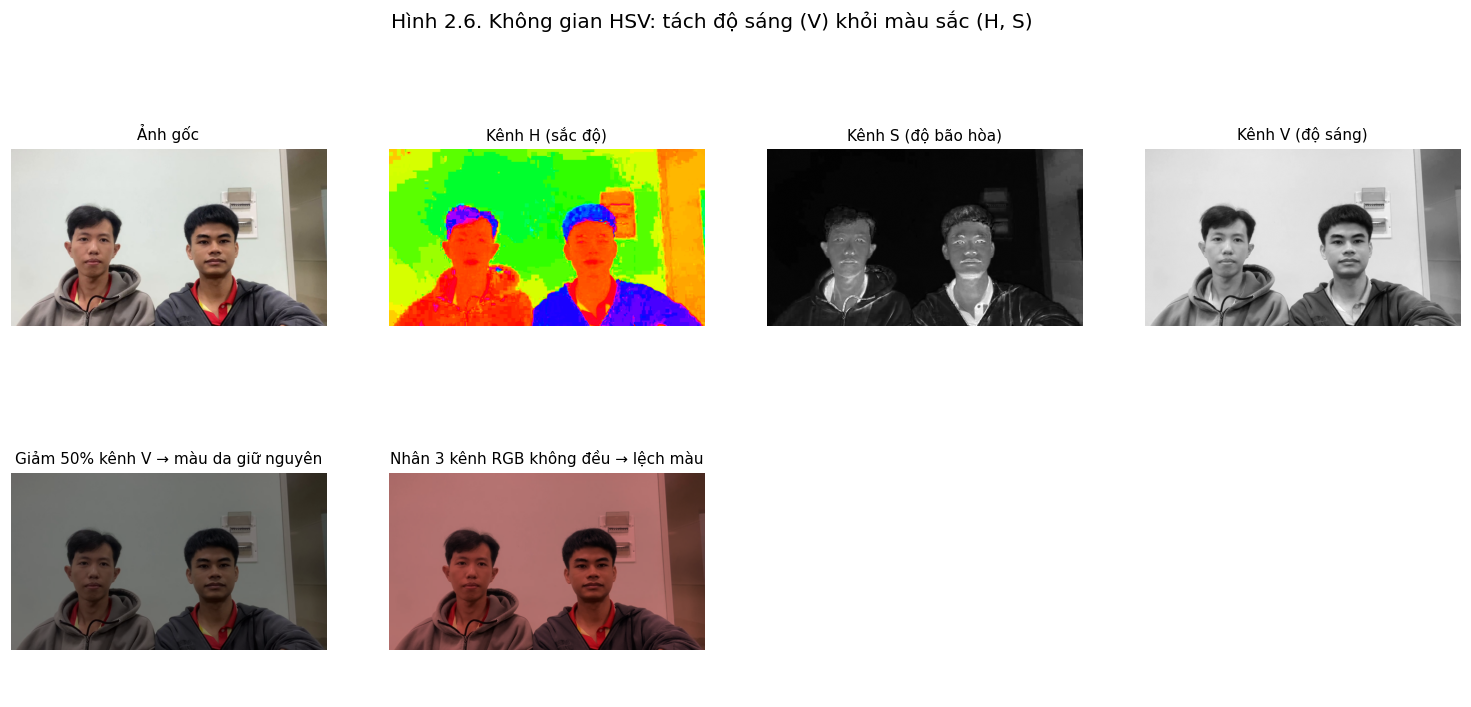

In [ ]:
# 3.1 Tách kênh H, S, V và minh họa việc giảm độ sáng chỉ trên kênh V (giữ nguyên màu da)
demo_name = img_df[img_df.class_name == 'normal'].image.iloc[0] if (img_df.class_name == 'normal').any() else img_df.image.iloc[0]
img_bgr = cv2.imread(str(RAW_IMAGES / demo_name))
hsv = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2HSV)
h, s, v = cv2.split(hsv)
v_dark = np.clip(v.astype(np.float32) * 0.5, 0, 255).astype(np.uint8)
img_dark_hsv = cv2.cvtColor(cv2.merge([h, s, v_dark]), cv2.COLOR_HSV2BGR)
img_dark_rgbscale = np.clip(img_bgr.astype(np.float32) * [0.5, 0.5, 0.8], 0, 255).astype(np.uint8)   # trừ ví dụ: nhân KHÔNG đều 3 kênh -> lệch màu

fig, axes = plt.subplots(2, 4, figsize=(17, 7))
panels = [
    ('Ảnh gốc', img_bgr[..., ::-1], None), ('Kênh H (sắc độ)', h, 'hsv'),
    ('Kênh S (độ bão hòa)', s, 'gray'), ('Kênh V (độ sáng)', v, 'gray'),
    ('Giảm 50% kênh V → màu da giữ nguyên', img_dark_hsv[..., ::-1], None),
    ('Nhân 3 kênh RGB không đều → lệch màu', img_dark_rgbscale[..., ::-1], None),
]
for ax, (title, im, cmap) in zip(axes.ravel(), panels):
    ax.imshow(im, cmap=cmap)
    ax.set_title(title, fontsize=10)
    ax.axis('off')
axes[1, 2].axis('off'); axes[1, 3].axis('off')
fig.suptitle('Hình 2.6. Không gian HSV: tách độ sáng (V) khỏi màu sắc (H, S)', y=1.0)
save_fig(fig, 'hinh_2_6_hsv_kenh')

Đã lưu hình: /content/drive/MyDrive/drowsiness_yolov8/report_assets/hinh_2_4_clahe_truoc_sau.png


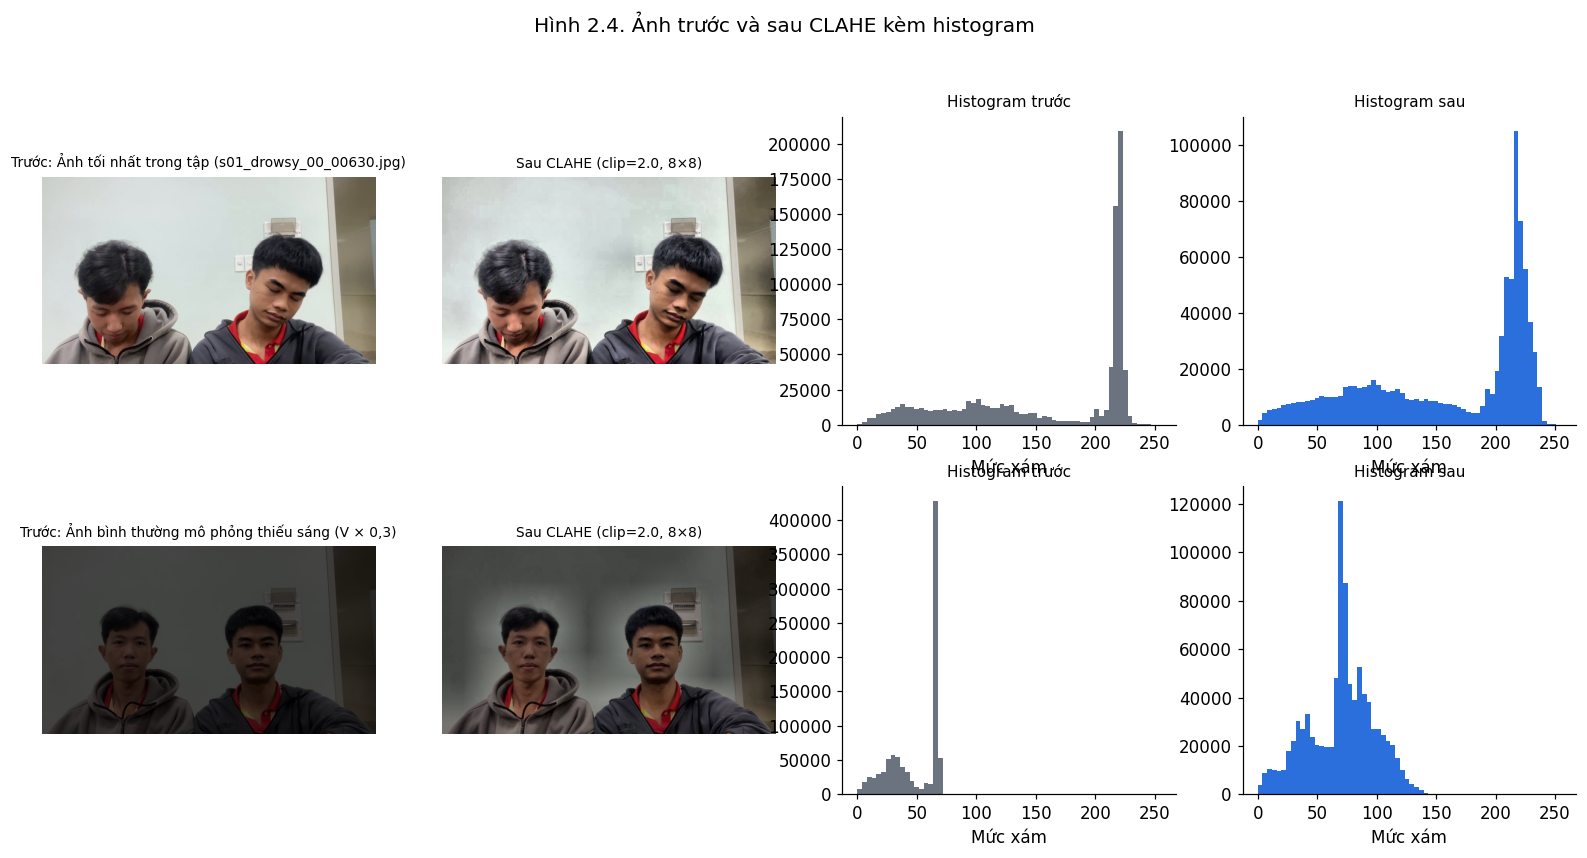

In [ ]:
# 3.2 CLAHE: cân bằng histogram cục bộ trên kênh V (không đụng đến H, S nên không lệch màu)
def apply_clahe(img_bgr, clip=2.0, tile=(8, 8)):
    hsv = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2HSV)
    h, s, v = cv2.split(hsv)
    v = cv2.createCLAHE(clipLimit=clip, tileGridSize=tile).apply(v)
    return cv2.cvtColor(cv2.merge([h, s, v]), cv2.COLOR_HSV2BGR)

def maybe_clahe(img_bgr, thresh=DARK_T, clip=2.0):
    """CLAHE có điều kiện: chỉ bật khi khung hình tối (độ sáng TB kênh V < thresh)."""
    v_mean = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2HSV)[..., 2].mean()
    return apply_clahe(img_bgr, clip) if v_mean < thresh else img_bgr

def simulate_dark(img_bgr, factor=0.3):
    hsv = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2HSV)
    hsv[..., 2] = np.clip(hsv[..., 2].astype(np.float32) * factor, 0, 255).astype(np.uint8)
    return cv2.cvtColor(hsv, cv2.COLOR_HSV2BGR)

darkest = img_df.brightness.idxmin()
cases = [
    (f'Ảnh tối nhất trong tập ({darkest})', cv2.imread(str(RAW_IMAGES / darkest))),
    ('Ảnh bình thường mô phỏng thiếu sáng (V × 0,3)', simulate_dark(img_bgr, 0.3)),
]
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for r, (title, im) in enumerate(cases):
    after = apply_clahe(im)
    axes[r, 0].imshow(im[..., ::-1]); axes[r, 0].set_title(f'Trước: {title}', fontsize=9); axes[r, 0].axis('off')
    axes[r, 1].imshow(after[..., ::-1]); axes[r, 1].set_title('Sau CLAHE (clip=2.0, 8×8)', fontsize=9); axes[r, 1].axis('off')
    for ax, data, lab, col in [(axes[r, 2], im, 'Histogram trước', '#6b7280'), (axes[r, 3], after, 'Histogram sau', '#2a6fdb')]:
        g = cv2.cvtColor(data, cv2.COLOR_BGR2GRAY)
        ax.hist(g.ravel(), bins=64, range=(0, 255), color=col)
        ax.set_title(lab, fontsize=10)
        ax.set_xlabel('Mức xám')
fig.suptitle('Hình 2.4. Ảnh trước và sau CLAHE kèm histogram', y=1.0)
save_fig(fig, 'hinh_2_4_clahe_truoc_sau')

## Phần 4. Chia tập theo phiên chụp (Session-based split) và kiểm tra rò rỉ dữ liệu (mục 2.6)

Ảnh chụp liên tiếp từ webcam gần như giống hệt nhau. Nếu xáo trộn ngẫu nhiên từng ảnh, ảnh ở tập kiểm thử sẽ có "bản sao" ở tập huấn luyện và mAP bị cao ảo.
Vì vậy toàn bộ ảnh của **một phiên/một người** nằm trong **đúng một tập**. Nếu chỉ có 1–2 phiên (ví dụ mỗi lớp một video của cùng một người), notebook chuyển sang **chia theo khối thời gian**: mỗi video cắt thành các khối vài giây, các khối được chia vào train/val/test và bỏ đoạn đệm ở ranh giới. Cách này chỉ kiểm tra được khả năng tổng quát trong cùng một người và một nền; hãy nêu rõ trong báo cáo. Ô dưới còn **đo bằng số liệu** mức rò rỉ của cách chia ngẫu nhiên so với cách chia theo phiên.

Số phiên/người: 1 → chế độ chia: THEO KHỐI THỜI GIAN trong từng video
Bỏ 600 khung sát ranh giới giữa các khối thuộc tập khác nhau (đoạn đệm 1.0s) để giảm rò rỉ.
⚠️ Chia theo khối thời gian vẫn dùng chung một người và một nền ở cả train và test, nên mAP sẽ cao hơn thực tế khi gặp người mới. Hãy ghi rõ giới hạn này trong báo cáo (mục 2.8) hoặc quay thêm người khác.


,% ảnh val có ảnh gần trùng ở train,% ảnh test có ảnh gần trùng ở train
Chia ngẫu nhiên từng ảnh,100.0,100.0
Chia theo phiên/người,95.9,100.0


Đã lưu bảng: /content/drive/MyDrive/drowsiness_yolov8/report_assets/bang_2_3_ro_ri_du_lieu.csv
Đọc kết quả: dòng "Chia theo phiên" phải thấp hơn rõ rệt dòng "Chia ngẫu nhiên". Giá trị cao nghĩa là các phiên vẫn quá giống nhau (cùng nền, cùng tư thế).
path: /content/dataset_split
train: train/images
val: val/images
test: test/images
nc: 3
names: ['normal', 'yawn', 'drowsy']



class_name,Số phiên/khối,normal,yawn,drowsy,Tổng ảnh
split,,,,,
train,14,360,396,343,1099
val,3,73,60,60,193
test,3,60,60,60,180


Đã lưu bảng: /content/drive/MyDrive/drowsiness_yolov8/report_assets/bang_chia_tap.csv
Đã lưu hình: /content/drive/MyDrive/drowsiness_yolov8/report_assets/bieu_do_chia_tap.png


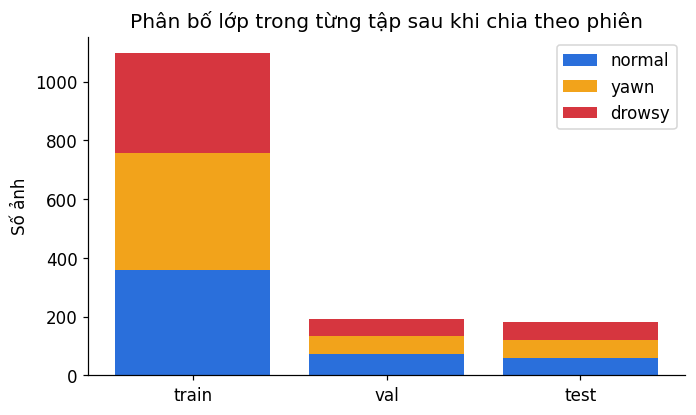

In [ ]:
# 4.1 Chia theo phiên + kiểm tra ảnh gần trùng bằng băm cảm nhận (dHash)
SPLITS = ['train', 'val', 'test']
BLOCK_SEC = 4.0      # độ dài mỗi khối thời gian (chế độ chia theo khối)
GUARD_S = 1.0        # bỏ các khung sát ranh giới giữa hai khối thuộc hai tập khác nhau

HAS_META = all(c in img_df.columns for c in ('video', 't_sec')) and img_df.t_sec.notna().all()
n_sessions = img_df.session.nunique()
SPLIT_MODE = 'session' if n_sessions >= 3 else 'temporal'
if SPLIT_MODE == 'temporal':
    assert HAS_META, ('Chỉ có <3 phiên và dữ liệu không đến từ video (không có frames_meta.csv): không thể chia 3 tập đáng tin. '
                      'Hãy thêm phiên/người hoặc tạo dữ liệu từ video ở Phần 1.')
print(f'Số phiên/người: {n_sessions} → chế độ chia: {"THEO PHIÊN/NGƯỜI" if SPLIT_MODE == "session" else "THEO KHỐI THỜI GIAN trong từng video"}')

def make_split(seed):
    sess = img_df.groupby('session').size().to_dict()
    ids = sorted(sess)
    random.Random(seed).shuffle(ids)
    total = sum(sess.values())
    t_train, t_val = SPLIT_RATIOS[0] * total, (SPLIT_RATIOS[0] + SPLIT_RATIOS[1]) * total
    mapping, cum = {}, 0
    for s in ids:
        mapping[s] = 'train' if cum < t_train else ('val' if cum < t_val else 'test')
        cum += sess[s]
    return mapping

def score_split(mapping):
    sp = img_df.session.map(mapping)
    ratio_dev = sum(abs((sp == s).mean() - r) for s, r in zip(SPLITS, SPLIT_RATIOS))
    missing = sum(1 for s in SPLITS for c in range(NC) if ((sp == s) & (img_df.cls == c)).sum() == 0)
    return ratio_dev + 10 * missing

def temporal_split(seed):
    """Mỗi video cắt thành các khối BLOCK_SEC giây; khối được xáo trộn rồi chia ~70/15/15 trong CHÍNH video đó,
    nên mọi tập đều có đủ ba lớp."""
    rng = random.Random(seed)
    out = {}
    for vid, g in img_df.groupby('video'):
        blocks = sorted(g.block.unique())
        assert len(blocks) >= 3, f'Video {vid} chỉ có {len(blocks)} khối {BLOCK_SEC}s: quá ngắn. Giảm BLOCK_SEC hoặc dùng video dài hơn.'
        rng.shuffle(blocks)
        n_test = max(1, round(SPLIT_RATIOS[2] * len(blocks)))
        n_val = max(1, round(SPLIT_RATIOS[1] * len(blocks)))
        for i, b in enumerate(blocks):
            out[(vid, b)] = 'test' if i < n_test else ('val' if i < n_test + n_val else 'train')
    return out

if SPLIT_MODE == 'session':
    best_seed = min(range(300), key=lambda sd: score_split(make_split(sd)))
    session_map = make_split(best_seed)
    img_df['split'] = img_df.session.map(session_map)
    img_df['unit'] = img_df.session
    print(f'Chọn hạt giống chia = {best_seed}, điểm lệch = {score_split(session_map):.3f}')
else:
    img_df['block'] = (img_df.t_sec // BLOCK_SEC).astype(int)
    split_of = temporal_split(SEED)
    img_df['split'] = [split_of[(v, b)] for v, b in zip(img_df.video, img_df.block)]
    img_df['unit'] = img_df.video.astype(str) + '#b' + img_df.block.astype(str)

    def keep_row(v, b, t):
        off, s = t - b * BLOCK_SEC, split_of[(v, b)]
        if off < GUARD_S and split_of.get((v, b - 1), s) != s:
            return False
        if (BLOCK_SEC - off) <= GUARD_S and split_of.get((v, b + 1), s) != s:
            return False
        return True

    keep = np.array([keep_row(v, b, t) for v, b, t in zip(img_df.video, img_df.block, img_df.t_sec)])
    print(f'Bỏ {int((~keep).sum())} khung sát ranh giới giữa các khối thuộc tập khác nhau (đoạn đệm {GUARD_S}s) để giảm rò rỉ.')
    img_df = img_df[keep]
    print('⚠️ Chia theo khối thời gian vẫn dùng chung một người và một nền ở cả train và test, nên mAP sẽ cao hơn thực tế khi gặp người mới. '
          'Hãy ghi rõ giới hạn này trong báo cáo (mục 2.8) hoặc quay thêm người khác.')

# --- dHash 64-bit cho mọi ảnh
def dhash(path):
    g = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)
    g = cv2.resize(g, (9, 8), interpolation=cv2.INTER_AREA)
    bits = (g[:, 1:] > g[:, :-1]).flatten()
    return int(''.join('1' if b else '0' for b in bits), 2)

with ThreadPoolExecutor(8) as ex:
    hashes = np.array(list(ex.map(lambda n: dhash(RAW_IMAGES / n), img_df.image)), dtype=np.uint64)
hash_of = dict(zip(img_df.image, hashes))
POP = np.array([bin(i).count('1') for i in range(256)], dtype=np.uint8)

def min_hamming(a, b, chunk=400):
    """Với mỗi hash trong a, khoảng cách Hamming nhỏ nhất tới tập b."""
    out = np.empty(len(a), dtype=np.int32)
    for i in range(0, len(a), chunk):
        x = np.bitwise_xor(a[i:i + chunk, None], b[None, :])
        out[i:i + chunk] = POP[x.view(np.uint8).reshape(x.shape[0], x.shape[1], 8)].sum(-1).min(1)
    return out

def leakage_report(split_series, thresh=4):
    tr = np.array([hash_of[n] for n in split_series[split_series == 'train'].index], dtype=np.uint64)
    res = {}
    for sp in ['val', 'test']:
        other = np.array([hash_of[n] for n in split_series[split_series == sp].index], dtype=np.uint64)
        d = min_hamming(other, tr)
        res[f'% ảnh {sp} có ảnh gần trùng ở train'] = round(100 * (d <= thresh).mean(), 1)
    return res

rng = np.random.default_rng(SEED)
random_split = pd.Series(rng.choice(SPLITS, size=len(img_df), p=SPLIT_RATIOS), index=img_df.index)
leak_tbl = pd.DataFrame({
    'Chia ngẫu nhiên từng ảnh': leakage_report(random_split),
    'Chia theo phiên/người': leakage_report(img_df.split),
}).T
display(leak_tbl)
save_table(leak_tbl, 'bang_2_3_ro_ri_du_lieu')
RESULTS['leakage'] = leak_tbl
print('Đọc kết quả: dòng "Chia theo phiên" phải thấp hơn rõ rệt dòng "Chia ngẫu nhiên". Giá trị cao nghĩa là các phiên vẫn quá giống nhau (cùng nền, cùng tư thế).')

# --- Sao chép ảnh/nhãn vào cấu trúc YOLO và ghi data.yaml
shutil.rmtree(WORK, ignore_errors=True)
for sp in SPLITS:
    (WORK / sp / 'images').mkdir(parents=True, exist_ok=True)
    (WORK / sp / 'labels').mkdir(parents=True, exist_ok=True)
for name, sp in img_df.split.items():
    shutil.copy2(RAW_IMAGES / name, WORK / sp / 'images' / name)
    shutil.copy2(RAW_LABELS / f'{Path(name).stem}.txt', WORK / sp / 'labels' / f'{Path(name).stem}.txt')

DATA_YAML.write_text(
    f'path: {WORK}\ntrain: train/images\nval: val/images\ntest: test/images\nnc: {NC}\nnames: {CLASS_NAMES}\n'
)
print(DATA_YAML.read_text())

split_tbl = pd.crosstab(img_df.split, img_df.class_name).reindex(index=SPLITS, columns=CLASS_NAMES)
split_tbl.insert(0, 'Số phiên/khối', img_df.groupby('split').unit.nunique().reindex(SPLITS))
split_tbl['Tổng ảnh'] = split_tbl[CLASS_NAMES].sum(axis=1)
display(split_tbl)
save_table(split_tbl, 'bang_chia_tap')
RESULTS['split'] = split_tbl

fig, ax = plt.subplots(figsize=(7, 4))
bottom = np.zeros(len(SPLITS))
for name in CLASS_NAMES:
    vals = split_tbl[name].values
    ax.bar(SPLITS, vals, bottom=bottom, color=CLASS_COLORS[name], label=name)
    bottom += vals
ax.set_ylabel('Số ảnh'); ax.set_title('Phân bố lớp trong từng tập sau khi chia theo phiên')
ax.legend()
save_fig(fig, 'bieu_do_chia_tap')

## Phần 5. Huấn luyện YOLOv8 (mục 3.2 – 3.3, 4.3)

In [ ]:
# 5.1 Hàm huấn luyện + chạy mô hình cơ sở (YOLOv8n, học chuyển giao từ COCO)
def train_model(weights, name, epochs, imgsz=IMGSZ, batch=BATCH, extra=None):
    set_seed()
    model = YOLO(weights)
    args = dict(
        data=str(DATA_YAML), epochs=epochs, imgsz=imgsz, batch=batch, device=DEVICE,
        patience=PATIENCE, seed=SEED, deterministic=True, project=str(RUNS), name=name,
        exist_ok=True, plots=True, workers=2, verbose=False,
    )
    args.update(extra or {})
    t0 = time.time()
    model.train(**args)
    print(f'⏱ Thời gian huấn luyện: {(time.time() - t0) / 60:.1f} phút')
    return model

FORCE_RETRAIN = False
BEST = RUNS / RUN_NAME / 'weights' / 'best.pt'
if BEST.exists() and not FORCE_RETRAIN:
    print('Đã có best.pt, bỏ qua huấn luyện:', BEST, '(đặt FORCE_RETRAIN = True để huấn luyện lại)')
else:
    train_model('yolov8n.pt', RUN_NAME, EPOCHS)
print('best.pt tồn tại:', BEST.exists())

Ultralytics 8.4.202 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/dataset_split/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=ngu_gat_yolov8n, nbs=64, nms=None, opset=None, optimize=F

Đã lưu hình: /content/drive/MyDrive/drowsiness_yolov8/report_assets/bieu_do_4_1_huan_luyen.png


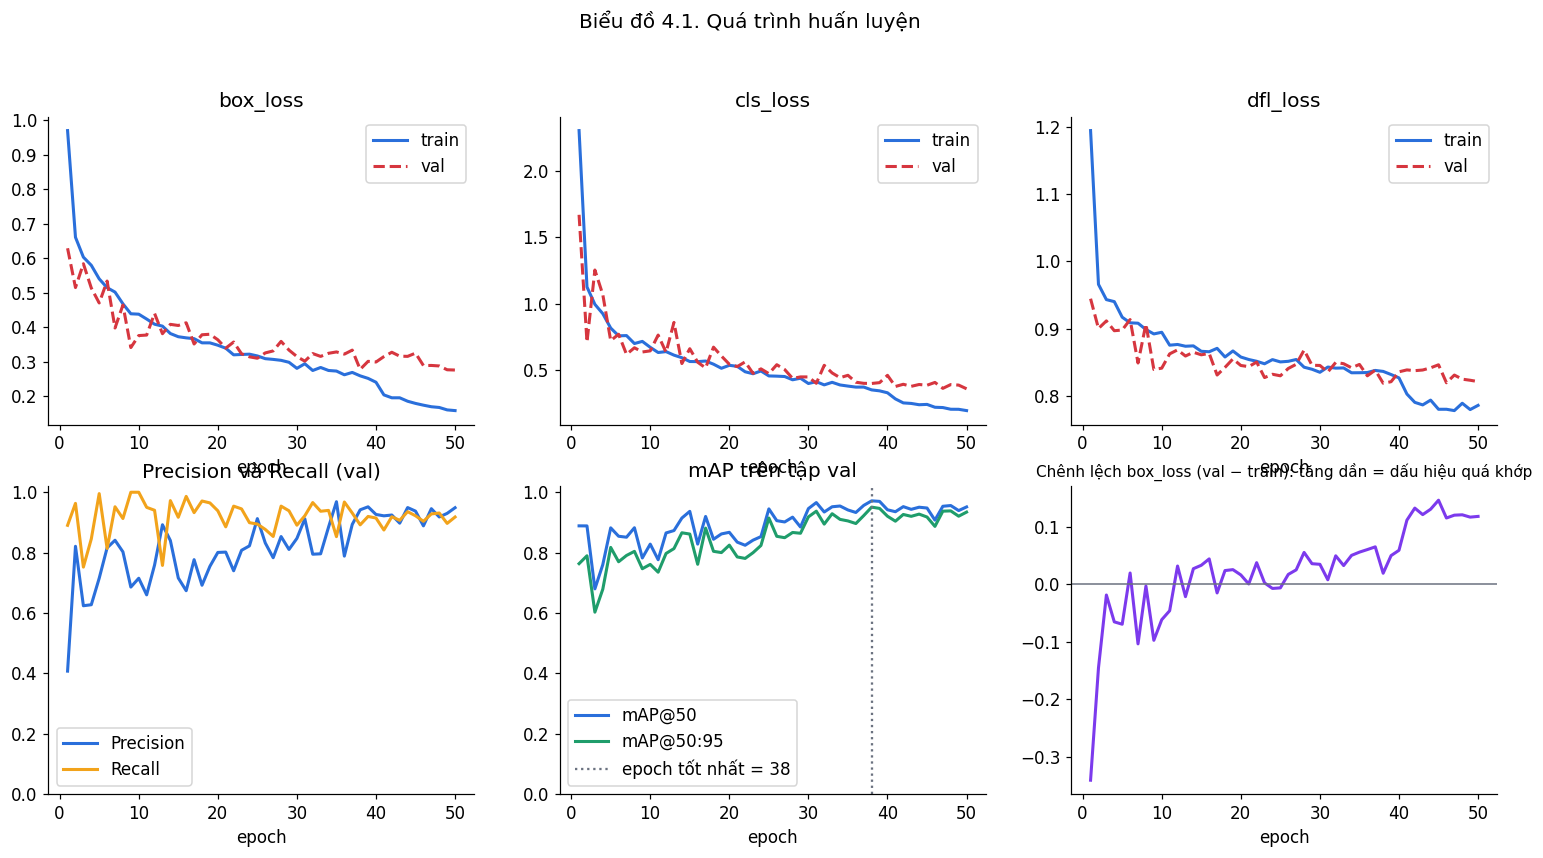

Epoch tốt nhất: 38 | mAP@50 = 0.972 | mAP@50:95 = 0.951 (tập val)
Cảnh báo: nếu mAP@50 trên val gần 1.0 ngay từ các epoch đầu, hãy nghi ngờ rò rỉ dữ liệu (xem lại bảng ở mục 4.1).


In [ ]:
# 5.2 Biểu đồ huấn luyện (Biểu đồ 4.1): mất mát train/val và các chỉ số qua từng epoch
def plot_training_curves(run_name, fig_name='bieu_do_4_1_huan_luyen'):
    df = pd.read_csv(RUNS / run_name / 'results.csv')
    df.columns = [c.strip() for c in df.columns]
    fig, axes = plt.subplots(2, 3, figsize=(17, 8))
    for ax, k in zip(axes[0], ['box_loss', 'cls_loss', 'dfl_loss']):
        ax.plot(df['epoch'], df[f'train/{k}'], color='#2a6fdb', lw=2, label='train')
        ax.plot(df['epoch'], df[f'val/{k}'], color='#d6363f', lw=2, ls='--', label='val')
        ax.set_title(k); ax.set_xlabel('epoch'); ax.legend()
    ax = axes[1, 0]
    ax.plot(df['epoch'], df['metrics/precision(B)'], color='#2a6fdb', lw=2, label='Precision')
    ax.plot(df['epoch'], df['metrics/recall(B)'], color='#f2a31b', lw=2, label='Recall')
    ax.set_title('Precision và Recall (val)'); ax.set_xlabel('epoch'); ax.legend(); ax.set_ylim(0, 1.02)
    ax = axes[1, 1]
    ax.plot(df['epoch'], df['metrics/mAP50(B)'], color='#2a6fdb', lw=2, label='mAP@50')
    ax.plot(df['epoch'], df['metrics/mAP50-95(B)'], color='#1f9d6b', lw=2, label='mAP@50:95')
    best_ep = int(df['metrics/mAP50-95(B)'].idxmax())
    ax.axvline(df['epoch'].iloc[best_ep], color='#6b7280', ls=':', label=f'epoch tốt nhất = {int(df["epoch"].iloc[best_ep])}')
    ax.set_title('mAP trên tập val'); ax.set_xlabel('epoch'); ax.legend(); ax.set_ylim(0, 1.02)
    ax = axes[1, 2]
    gap = df['val/box_loss'] - df['train/box_loss']
    ax.plot(df['epoch'], gap, color='#7c3aed', lw=2)
    ax.axhline(0, color='#6b7280', lw=1)
    ax.set_title('Chênh lệch box_loss (val − train): tăng dần = dấu hiệu quá khớp'); ax.set_xlabel('epoch')
    ax.title.set_fontsize(10)
    fig.suptitle('Biểu đồ 4.1. Quá trình huấn luyện', y=1.0)
    save_fig(fig, fig_name)
    return df

curves = plot_training_curves(RUN_NAME)
best_row = curves.loc[curves['metrics/mAP50-95(B)'].idxmax()]
print(f"Epoch tốt nhất: {int(best_row['epoch'])} | mAP@50 = {best_row['metrics/mAP50(B)']:.3f} | mAP@50:95 = {best_row['metrics/mAP50-95(B)']:.3f} (tập val)")
RESULTS['best_epoch'] = int(best_row['epoch'])
print('Cảnh báo: nếu mAP@50 trên val gần 1.0 ngay từ các epoch đầu, hãy nghi ngờ rò rỉ dữ liệu (xem lại bảng ở mục 4.1).')

## Phần 6. Đánh giá định lượng trên tập kiểm thử (mục 4.2, 4.4, 4.5)

In [ ]:
# 6.1 Hàm đánh giá dùng chung + Bảng 4.1 (tổng hợp) và Bảng 4.2 (theo lớp)
test_counts = Counter()
for lp in (WORK / 'test' / 'labels').glob('*.txt'):
    for line in lp.read_text().splitlines():
        if line.strip():
            test_counts[int(line.split()[0])] += 1

def eval_model(weights, data=DATA_YAML, split='test', name='eval', conf=0.001, iou=0.6, plots=False):
    model = YOLO(str(weights))
    m = model.val(data=str(data), split=split, imgsz=IMGSZ, conf=conf, iou=iou, device=DEVICE,
                  plots=plots, project=str(RUNS), name=name, exist_ok=True, verbose=False)
    rows = []
    for i, c in enumerate(m.box.ap_class_index):
        rows.append({'Lớp': m.names[int(c)], 'Precision': m.box.p[i], 'Recall': m.box.r[i],
                     'AP@50': m.box.ap50[i], 'AP@50:95': m.box.ap[i]})
    per_class = pd.DataFrame(rows).set_index('Lớp')
    overall = {'Precision': float(m.box.mp), 'Recall': float(m.box.mr), 'mAP@50': float(m.box.map50), 'mAP@50:95': float(m.box.map)}
    return m, overall, per_class

best_model = YOLO(str(BEST))
m_test, overall, per_class = eval_model(BEST, split='test', name='eval_test', plots=True)

per_class.insert(0, 'Số hộp test', [test_counts.get(CLASS_NAMES.index(n), 0) for n in per_class.index])
overall_tbl = pd.DataFrame([overall], index=['Toàn bộ (tập test)']).round(3)
display(overall_tbl)
display(per_class.round(3))
save_table(overall_tbl, 'bang_4_1_tong_hop')
save_table(per_class.round(3), 'bang_4_2_theo_lop')
RESULTS['overall'] = overall_tbl
RESULTS['per_class'] = per_class.round(3)

# Chọn ngưỡng độ tin cậy tại điểm F1 cao nhất (mục 3.6)
try:
    f1c = np.mean(m_test.box.f1_curve, axis=0)
    px = np.asarray(m_test.box.px)
    CONF_BEST = float(px[int(np.argmax(f1c))])
    print(f'Ngưỡng conf tại F1 cao nhất = {CONF_BEST:.3f} (F1 = {f1c.max():.3f})')
    CONF_INFER = float(np.clip(CONF_BEST, 0.1, 0.9))
except Exception as e:
    print('Không lấy được đường cong F1, giữ CONF_INFER =', CONF_INFER, '|', e)
RESULTS['conf_best'] = CONF_INFER

Ultralytics 8.4.202 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,133,193 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1988.6±910.4 MB/s, size: 98.5 KB)
val: Scanning /content/dataset_split/test/labels... 180 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 180/180 2.0Kit/s 0.1s
val: New cache created: /content/dataset_split/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 12/12 4.4it/s 2.8s
                   all        180        180      0.688      0.828       0.68      0.642
Speed: 1.4ms preprocess, 4.1ms inference, 0.0ms loss, 1.7ms postprocess per image
Results saved to /content/drive/MyDrive/drowsiness_yolov8/runs/eval_test


,Precision,Recall,mAP@50,mAP@50:95
Toàn bộ (tập test),0.688,0.828,0.68,0.642


,Số hộp test,Precision,Recall,AP@50,AP@50:95
Lớp,,,,,
normal,60,0.501,0.983,0.682,0.645
yawn,60,0.985,1.000,0.995,0.928
drowsy,60,0.579,0.500,0.363,0.352


Đã lưu bảng: /content/drive/MyDrive/drowsiness_yolov8/report_assets/bang_4_1_tong_hop.csv
Đã lưu bảng: /content/drive/MyDrive/drowsiness_yolov8/report_assets/bang_4_2_theo_lop.csv
Ngưỡng conf tại F1 cao nhất = 0.051 (F1 = 0.737)


Đã lưu hình: /content/drive/MyDrive/drowsiness_yolov8/report_assets/hinh_4_1_ma_tran_nham_lan.png


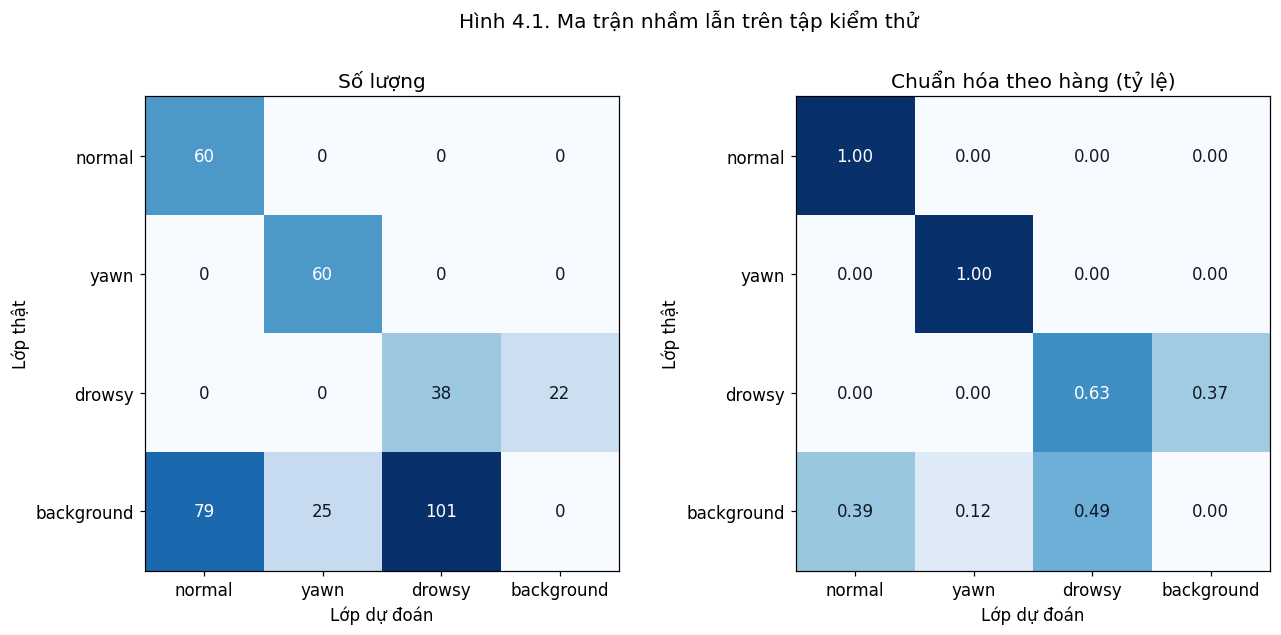

yawn bị nhầm thành drowsy: 0.0% | drowsy bị nhầm thành yawn: 0.0%
normal bị nhầm thành drowsy: 0.0% | drowsy bị nhầm thành normal: 0.0%


In [ ]:
# 6.2 Ma trận nhầm lẫn (Hình 4.1) tự vẽ: hàng = lớp thật, cột = lớp dự đoán, chuẩn hóa theo hàng
cm = np.asarray(m_test.confusion_matrix.matrix).T      # Ultralytics lưu [dự đoán, thật] -> đổi thành [thật, dự đoán]
labels_cm = CLASS_NAMES + ['background']
cm_norm = cm / np.maximum(cm.sum(axis=1, keepdims=True), 1)
fig, axes = plt.subplots(1, 2, figsize=(14, 5.6))
for ax, data, title, fmt in [(axes[0], cm, 'Số lượng', '{:.0f}'), (axes[1], cm_norm, 'Chuẩn hóa theo hàng (tỷ lệ)', '{:.2f}')]:
    im = ax.imshow(data, cmap='Blues')
    ax.set_xticks(range(NC + 1)); ax.set_xticklabels(labels_cm)
    ax.set_yticks(range(NC + 1)); ax.set_yticklabels(labels_cm)
    ax.set_xlabel('Lớp dự đoán'); ax.set_ylabel('Lớp thật'); ax.set_title(title)
    for i in range(NC + 1):
        for j in range(NC + 1):
            ax.text(j, i, fmt.format(data[i, j]), ha='center', va='center',
                    color='white' if data[i, j] > data.max() * 0.55 else '#111827')
    for sp in ax.spines.values():
        sp.set_visible(True)
fig.suptitle('Hình 4.1. Ma trận nhầm lẫn trên tập kiểm thử', y=1.02)
save_fig(fig, 'hinh_4_1_ma_tran_nham_lan')

# Hai kiểu nhầm cần phân tích trong báo cáo (mục 4.4)
def rate(i, j):
    return cm_norm[CLASS_NAMES.index(i), CLASS_NAMES.index(j)]
print(f"yawn bị nhầm thành drowsy: {rate('yawn', 'drowsy'):.1%} | drowsy bị nhầm thành yawn: {rate('drowsy', 'yawn'):.1%}")
print(f"normal bị nhầm thành drowsy: {rate('normal', 'drowsy'):.1%} | drowsy bị nhầm thành normal: {rate('drowsy', 'normal'):.1%}")

Đã lưu hình: /content/drive/MyDrive/drowsiness_yolov8/report_assets/hinh_4_2_duong_cong.png


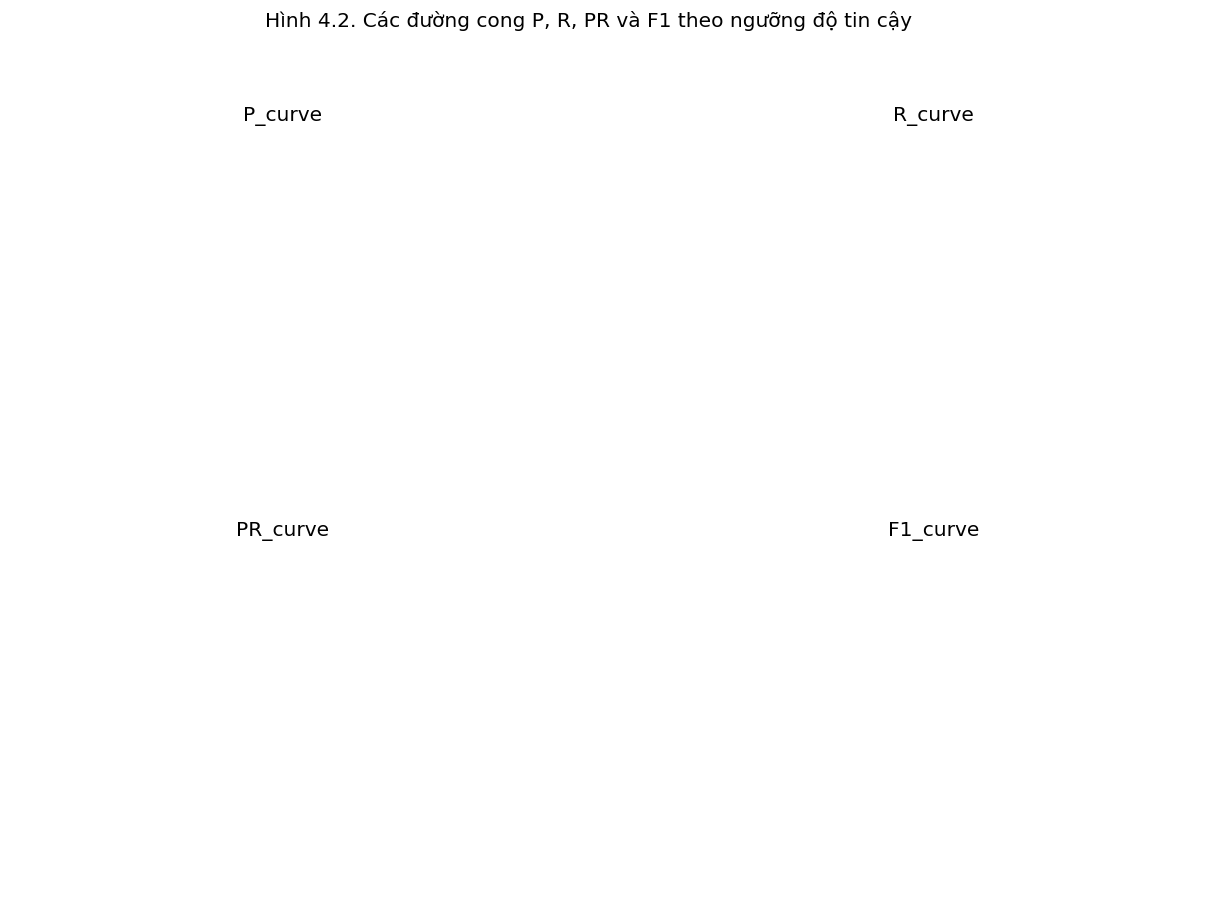

In [ ]:
# 6.3 Hiển thị các đường cong P, R, PR, F1 do Ultralytics sinh ra (Hình 4.2)
save_dir = Path(m_test.save_dir)
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, f in zip(axes.ravel(), ['P_curve.png', 'R_curve.png', 'PR_curve.png', 'F1_curve.png']):
    p = save_dir / f
    if p.exists():
        ax.imshow(plt.imread(p))
    ax.axis('off'); ax.set_title(f.replace('.png', ''))
fig.suptitle('Hình 4.2. Các đường cong P, R, PR và F1 theo ngưỡng độ tin cậy', y=1.0)
save_fig(fig, 'hinh_4_2_duong_cong')

## Phần 7. Kết quả định tính và phân tích trường hợp thất bại (mục 4.6, 4.7)

Đã lưu hình: /content/drive/MyDrive/drowsiness_yolov8/report_assets/hinh_4_3_truoc_sau.png


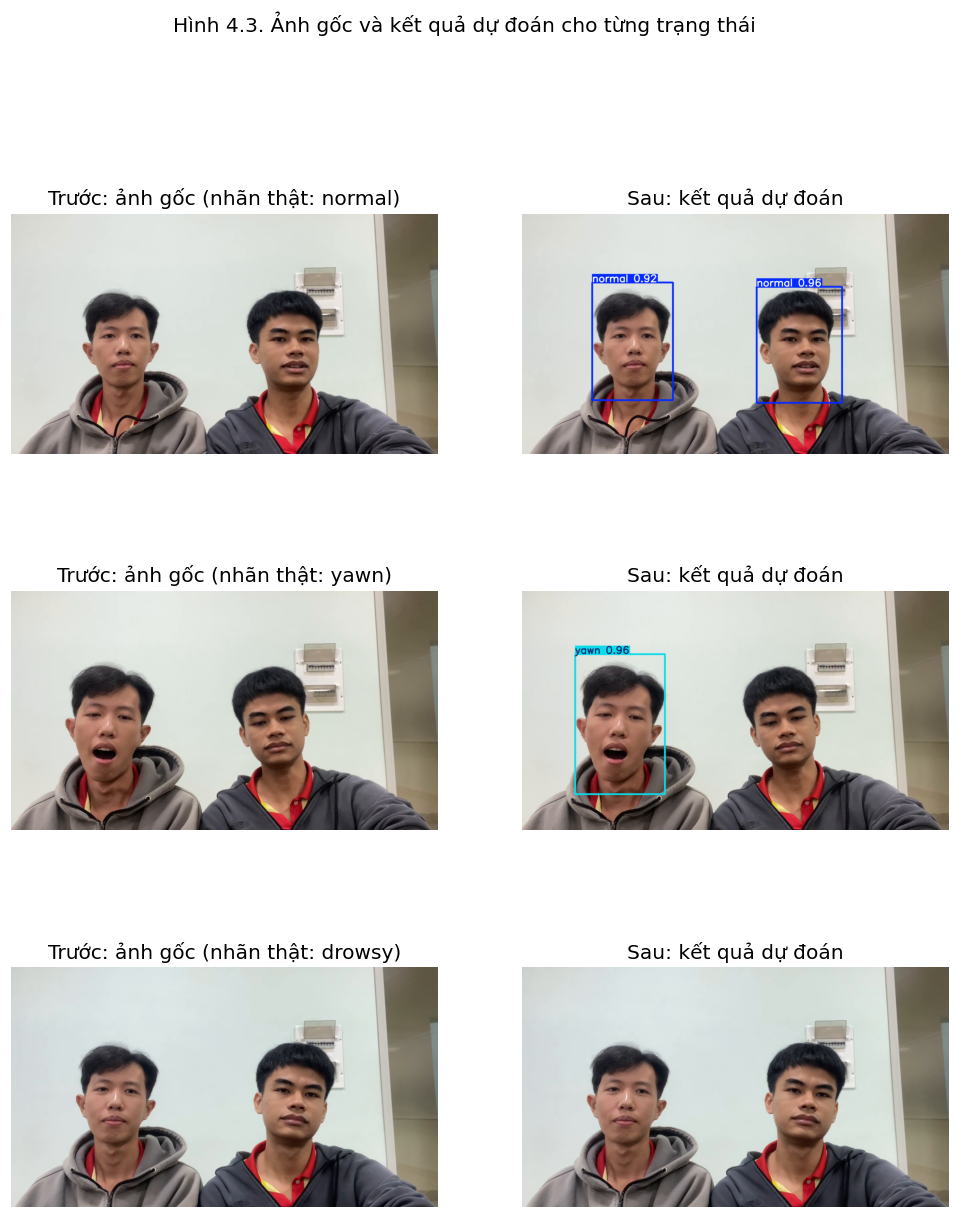

In [ ]:
# 7.1 Ảnh trước/sau cho từng trạng thái (Hình 4.3)
def predict_one(model, img_bgr, conf=None, device=DEVICE):
    return model.predict(img_bgr, conf=conf or CONF_INFER, imgsz=IMGSZ, device=device, verbose=False)[0]

test_paths = sorted((WORK / 'test' / 'images').glob('*.jpg'))
test_df = img_df[img_df.split == 'test']
fig, axes = plt.subplots(NC, 2, figsize=(11, 4.2 * NC))
for r, name in enumerate(CLASS_NAMES):
    sub = test_df[test_df.class_name == name]
    if sub.empty:
        continue
    pick = sub.image.iloc[len(sub) // 2]
    img = cv2.imread(str(WORK / 'test' / 'images' / pick))
    res = predict_one(best_model, img)
    axes[r, 0].imshow(img[..., ::-1]); axes[r, 0].set_title(f'Trước: ảnh gốc (nhãn thật: {name})'); axes[r, 0].axis('off')
    axes[r, 1].imshow(res.plot()[..., ::-1]); axes[r, 1].set_title('Sau: kết quả dự đoán'); axes[r, 1].axis('off')
fig.suptitle('Hình 4.3. Ảnh gốc và kết quả dự đoán cho từng trạng thái', y=1.0)
save_fig(fig, 'hinh_4_3_truoc_sau')

Số hộp kiểm thử: 180 | đúng: 147 | nhầm lớp: 0 | bỏ sót: 33
Đã lưu bảng: /content/drive/MyDrive/drowsiness_yolov8/report_assets/danh_sach_loi.csv
Đã lưu hình: /content/drive/MyDrive/drowsiness_yolov8/report_assets/hinh_4_5_loi_tieu_bieu.png


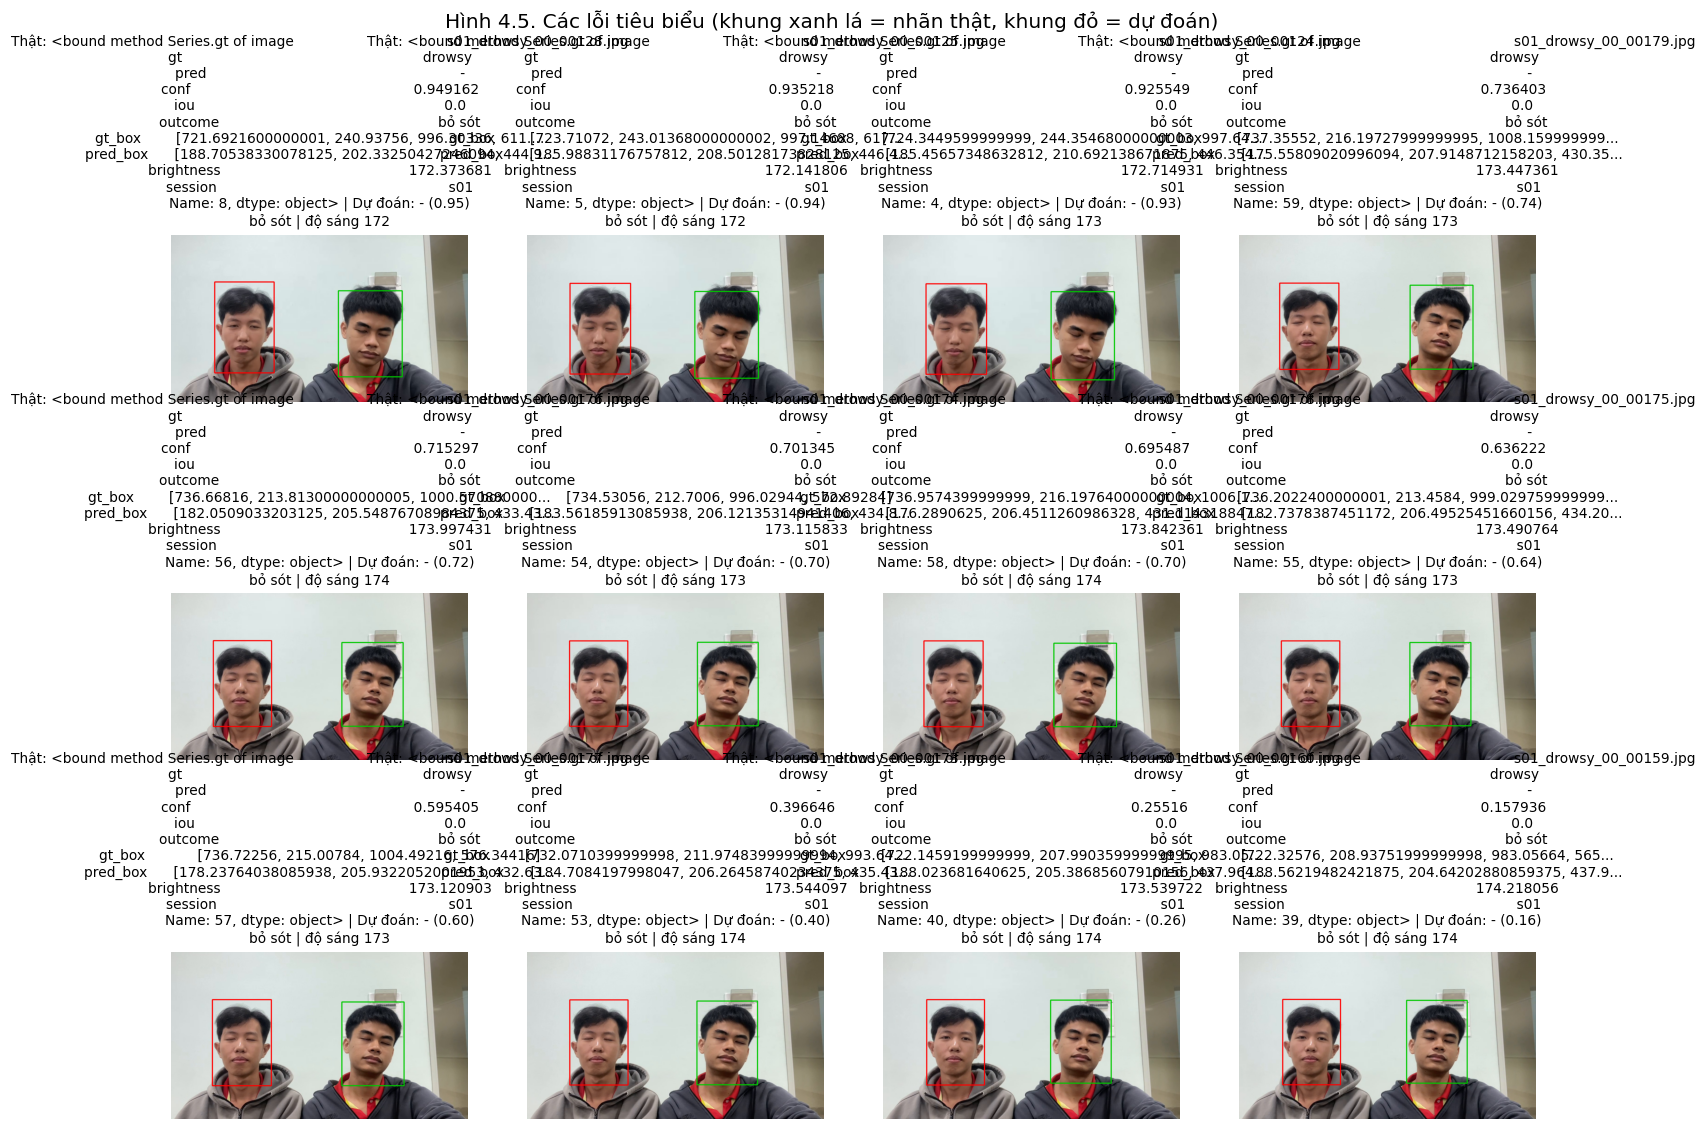

,Số hộp,Tỷ lệ lỗi (%)
nhom_sang,,
sáng (>120),180.0,18.3


,Số hộp,Tỷ lệ lỗi (%)
gt,,
normal,60.0,0.0
yawn,60.0,0.0
drowsy,60.0,55.0


Đã lưu hình: /content/drive/MyDrive/drowsiness_yolov8/report_assets/bieu_do_ty_le_loi.png


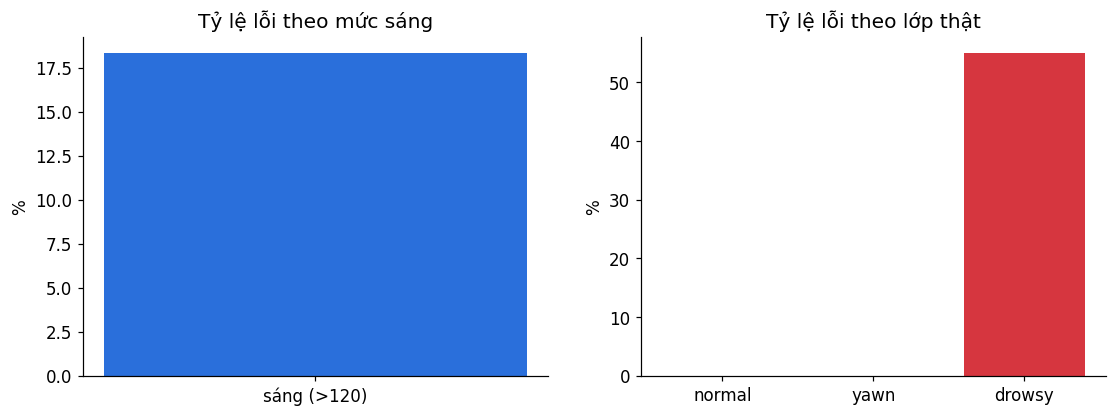

In [ ]:
# 7.2 Phân tích trường hợp thất bại: đối chiếu dự đoán với nhãn thật bằng IoU
def yolo_to_xyxy(xc, yc, w, h, W, H):
    return [(xc - w / 2) * W, (yc - h / 2) * H, (xc + w / 2) * W, (yc + h / 2) * H]

def iou_xyxy(a, b):
    ix1, iy1, ix2, iy2 = max(a[0], b[0]), max(a[1], b[1]), min(a[2], b[2]), min(a[3], b[3])
    inter = max(0, ix2 - ix1) * max(0, iy2 - iy1)
    union = (a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter
    return inter / union if union > 0 else 0

fail_rows = []
for res in best_model.predict([str(p) for p in test_paths], conf=CONF_INFER, imgsz=IMGSZ, device=DEVICE, stream=True, verbose=False):
    name = Path(res.path).name
    H, W = res.orig_shape
    gts = labels_df[labels_df.image == name]
    preds = [(b.xyxy[0].tolist(), int(b.cls), float(b.conf)) for b in res.boxes]
    for _, g in gts.iterrows():
        gb = yolo_to_xyxy(g.xc, g.yc, g.w, g.h, W, H)
        best = max(((iou_xyxy(gb, pb), pc, cf, pb) for pb, pc, cf in preds), default=(0, None, 0, None), key=lambda t: t[0])
        if best[0] < 0.5:
            outcome, pred_c = 'bỏ sót', None
        elif best[1] != int(g.cls):
            outcome, pred_c = 'nhầm lớp', best[1]
        else:
            outcome, pred_c = 'đúng', best[1]
        fail_rows.append(dict(image=name, gt=CLASS_NAMES[int(g.cls)], pred=CLASS_NAMES[pred_c] if pred_c is not None else '-',
                              conf=best[2], iou=best[0], outcome=outcome, gt_box=gb, pred_box=best[3],
                              brightness=img_df.loc[name, 'brightness'], session=img_df.loc[name, 'session']))
eval_df = pd.DataFrame(fail_rows)
errors = eval_df[eval_df.outcome != 'đúng'].sort_values('conf', ascending=False)
print(f'Số hộp kiểm thử: {len(eval_df)} | đúng: {(eval_df.outcome == "đúng").sum()} | nhầm lớp: {(eval_df.outcome == "nhầm lớp").sum()} | bỏ sót: {(eval_df.outcome == "bỏ sót").sum()}')
save_table(errors.drop(columns=['gt_box', 'pred_box']), 'danh_sach_loi', index=False)
RESULTS['errors'] = errors

# Lưới ảnh lỗi tiêu biểu (ưu tiên lỗi có độ tin cậy cao: mô hình "tự tin nhưng sai")
top = errors.head(12)
if len(top):
    cols = 4
    rows_n = math.ceil(len(top) / cols)
    fig, axes = plt.subplots(rows_n, cols, figsize=(16, 4 * rows_n))
    axes = np.atleast_2d(axes)
    for ax in axes.ravel():
        ax.axis('off')
    for ax, (_, e) in zip(axes.ravel(), top.iterrows()):
        img = cv2.imread(str(WORK / 'test' / 'images' / e.image))
        gb = [int(v) for v in e.gt_box]
        cv2.rectangle(img, (gb[0], gb[1]), (gb[2], gb[3]), (0, 200, 0), 3)
        if e.pred_box is not None:
            pb = [int(v) for v in e.pred_box]
            cv2.rectangle(img, (pb[0], pb[1]), (pb[2], pb[3]), (0, 0, 255), 3)
        ax.imshow(img[..., ::-1])
        ax.set_title(f'Thật: {e.gt} | Dự đoán: {e.pred} ({e.conf:.2f})\n{e.outcome} | độ sáng {e.brightness:.0f}', fontsize=9)
    fig.suptitle('Hình 4.5. Các lỗi tiêu biểu (khung xanh lá = nhãn thật, khung đỏ = dự đoán)', y=1.0)
    save_fig(fig, 'hinh_4_5_loi_tieu_bieu')
else:
    print('Không có lỗi nào trên tập test (hoặc tập test quá nhỏ). Hãy kiểm tra lại rò rỉ dữ liệu.')

# Tỷ lệ lỗi theo độ sáng và theo lớp thật: bằng chứng cho bảng 4.7
eval_df['nhom_sang'] = pd.cut(eval_df.brightness, [0, DARK_T, 120, 255], labels=[f'tối (<{DARK_T})', 'vừa (60-120)', 'sáng (>120)'])
by_bright = eval_df.groupby('nhom_sang', observed=True).apply(lambda d: pd.Series({'Số hộp': len(d), 'Tỷ lệ lỗi (%)': 100 * (d.outcome != 'đúng').mean()}))
by_class = eval_df.groupby('gt').apply(lambda d: pd.Series({'Số hộp': len(d), 'Tỷ lệ lỗi (%)': 100 * (d.outcome != 'đúng').mean()})).reindex(CLASS_NAMES)
display(by_bright.round(1)); display(by_class.round(1))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(by_bright.index.astype(str), by_bright['Tỷ lệ lỗi (%)'], color='#2a6fdb')
axes[0].set_title('Tỷ lệ lỗi theo mức sáng'); axes[0].set_ylabel('%')
axes[1].bar(by_class.index, by_class['Tỷ lệ lỗi (%)'], color=[CLASS_COLORS[c] for c in by_class.index])
axes[1].set_title('Tỷ lệ lỗi theo lớp thật'); axes[1].set_ylabel('%')
save_fig(fig, 'bieu_do_ty_le_loi')
RESULTS['err_by_brightness'] = by_bright.round(1)

## Phần 8. Thí nghiệm CLAHE trong điều kiện thiếu sáng (mục 4.6.1, Bảng 4.5)

Mô hình giữ nguyên, chỉ thay đổi tiền xử lý lúc suy luận: ảnh gốc, CLAHE (clipLimit 2.0), CLAHE (clipLimit 4.0).
Tập test được tách thành tập con **thiếu sáng** và tập con **bình thường** theo độ sáng trung bình.

Ít ảnh tối thật sự trong tập test, dùng 30% ảnh tối nhất (độ sáng <= 172.3) làm tập con "thiếu sáng".
Tập con thiếu sáng: 54 ảnh | tập con bình thường: 126 ảnh
Ultralytics 8.4.202 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,133,193 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2858.8±931.0 MB/s, size: 122.3 KB)
val: Scanning /content/subsets/thiếu sáng_7857/labels... 54 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 54/54 2.0Kit/s 0.0s
val: New cache created: /content/subsets/thiếu sáng_7857/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 4.6it/s 0.9s
                   all         54         54      0.813      0.924      0.826      0.777
Speed: 0.8ms preprocess, 4.6ms inference, 0.0ms loss, 1.4ms postprocess per image
Ultralytics 8.4.202 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model sum

,mAP@50 (thiếu sáng),mAP@50:95 (thiếu sáng),Recall drowsy (thiếu sáng),mAP@50 (bình thường),mAP@50:95 (bình thường)
Điều kiện suy luận,,,,,
Ảnh gốc,0.826,0.777,0.848,0.645,0.613
"CLAHE, clipLimit = 2,0",0.753,0.697,1.000,0.558,0.526
"CLAHE, clipLimit = 4,0",0.741,0.687,0.950,0.558,0.522


Đã lưu bảng: /content/drive/MyDrive/drowsiness_yolov8/report_assets/bang_4_5_clahe.csv
Đã lưu hình: /content/drive/MyDrive/drowsiness_yolov8/report_assets/bieu_do_4_clahe.png


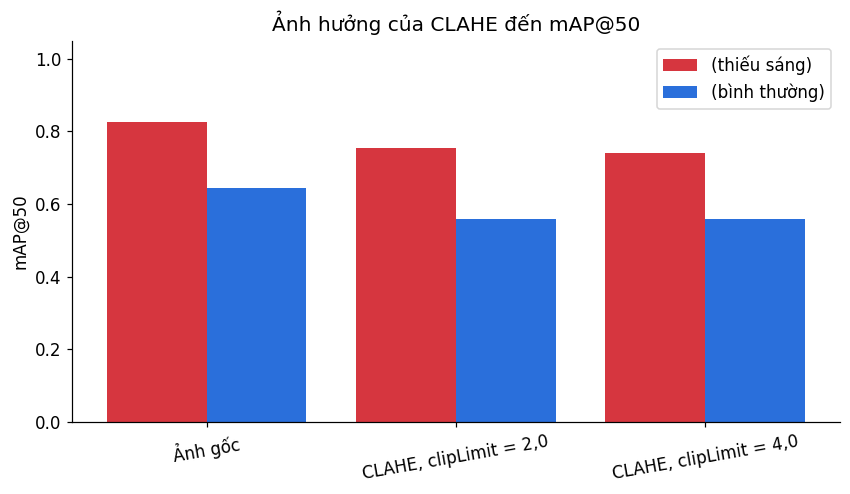

Chênh mAP@50 khi dùng CLAHE (clip 2.0): thiếu sáng -0.073, bình thường -0.087


In [ ]:
def make_subset_dataset(tag, names, transform=None):
    d = Path('/content/subsets') / tag
    shutil.rmtree(d, ignore_errors=True)
    (d / 'images').mkdir(parents=True); (d / 'labels').mkdir(parents=True)
    for n in names:
        img = cv2.imread(str(WORK / 'test' / 'images' / n))
        if transform is not None:
            img = transform(img)
        cv2.imwrite(str(d / 'images' / n), img)
        shutil.copy2(WORK / 'test' / 'labels' / f'{Path(n).stem}.txt', d / 'labels' / f'{Path(n).stem}.txt')
    y = d / 'data.yaml'
    y.write_text(f'path: {d}\ntrain: images\nval: images\nnc: {NC}\nnames: {CLASS_NAMES}\n')
    return y

thr = DARK_T
dark_names = test_df[test_df.brightness < thr].image.tolist()
if len(dark_names) < 20:
    thr = float(test_df.brightness.quantile(0.30))
    dark_names = test_df[test_df.brightness <= thr].image.tolist()
    print(f'Ít ảnh tối thật sự trong tập test, dùng 30% ảnh tối nhất (độ sáng <= {thr:.1f}) làm tập con "thiếu sáng".')
normal_names = [n for n in test_df.image if n not in set(dark_names)]
print(f'Tập con thiếu sáng: {len(dark_names)} ảnh | tập con bình thường: {len(normal_names)} ảnh')

conditions = {
    'Ảnh gốc': None,
    'CLAHE, clipLimit = 2,0': lambda im: apply_clahe(im, 2.0),
    'CLAHE, clipLimit = 4,0': lambda im: apply_clahe(im, 4.0),
}
clahe_rows = []
for cname, fn in conditions.items():
    row = {'Điều kiện suy luận': cname}
    for sub_tag, names in [('thiếu sáng', dark_names), ('bình thường', normal_names)]:
        if len(names) == 0:
            continue
        y = make_subset_dataset(f'{sub_tag}_{abs(hash(cname)) % 9999}', names, fn)
        _, ov, pc = eval_model(BEST, data=y, split='val', name='clahe_tmp')
        row[f'mAP@50 ({sub_tag})'] = ov['mAP@50']
        row[f'mAP@50:95 ({sub_tag})'] = ov['mAP@50:95']
        if sub_tag == 'thiếu sáng':
            row['Recall drowsy (thiếu sáng)'] = pc['Recall'].get('drowsy', np.nan)
    clahe_rows.append(row)
clahe_tbl = pd.DataFrame(clahe_rows).set_index('Điều kiện suy luận').round(3)
display(clahe_tbl)
save_table(clahe_tbl, 'bang_4_5_clahe')
RESULTS['clahe'] = clahe_tbl

cols_plot = [c for c in clahe_tbl.columns if c.startswith('mAP@50 (')]
fig, ax = plt.subplots(figsize=(9, 4.5))
x = np.arange(len(clahe_tbl)); w = 0.8 / max(1, len(cols_plot))
for k, c in enumerate(cols_plot):
    ax.bar(x + k * w, clahe_tbl[c], w, label=c.replace('mAP@50 ', ''), color=['#d6363f', '#2a6fdb'][k % 2])
ax.set_xticks(x + w * (len(cols_plot) - 1) / 2); ax.set_xticklabels(clahe_tbl.index, rotation=10)
ax.set_ylabel('mAP@50'); ax.set_ylim(0, 1.05); ax.legend(); ax.set_title('Ảnh hưởng của CLAHE đến mAP@50')
save_fig(fig, 'bieu_do_4_clahe')

if len(cols_plot) == 2:
    gain = clahe_tbl.iloc[1, clahe_tbl.columns.get_loc(cols_plot[0])] - clahe_tbl.iloc[0, clahe_tbl.columns.get_loc(cols_plot[0])]
    loss = clahe_tbl.iloc[1, clahe_tbl.columns.get_loc(cols_plot[1])] - clahe_tbl.iloc[0, clahe_tbl.columns.get_loc(cols_plot[1])]
    print(f'Chênh mAP@50 khi dùng CLAHE (clip 2.0): thiếu sáng {gain:+.3f}, bình thường {loss:+.3f}')
    if gain > 0 and loss < 0:
        print('→ Gợi ý kết luận: CLAHE giúp ở ảnh tối nhưng làm lệch phân bố ở ảnh bình thường; nên bật CLAHE CÓ ĐIỀU KIỆN (hàm maybe_clahe).')

## Phần 9. Thí nghiệm đối chứng (tùy chọn, tốn thời gian) — Bảng 4.3

Mỗi cấu hình chỉ đổi **một** yếu tố so với cơ sở. Đặt `RUN_ABLATION = True` để chạy (khoảng 10–30 phút mỗi cấu hình trên T4).

In [ ]:
RUN_ABLATION = False

def benchmark(weights, device=DEVICE, n=100, warmup=10):
    model = YOLO(str(weights))
    img = cv2.imread(str(test_paths[0]))
    for _ in range(warmup):
        model.predict(img, imgsz=IMGSZ, device=device, verbose=False)
    ts = []
    for _ in range(n):
        r = model.predict(img, imgsz=IMGSZ, device=device, verbose=False)[0]
        ts.append(sum(r.speed.values()))       # tiền xử lý + suy luận + hậu xử lý (ms)
    ms = float(np.mean(ts))
    return ms, 1000 / ms

NO_AUG = dict(hsv_h=0, hsv_s=0, hsv_v=0, fliplr=0, mosaic=0, translate=0, scale=0)
EXPERIMENTS = {
    'YOLOv8n, cơ sở (50 epoch)': (RUN_NAME, None),
    'YOLOv8n, 100 epoch': ('abl_n_100ep', dict(weights='yolov8n.pt', epochs=100)),
    'YOLOv8s (50 epoch)': ('abl_s_50ep', dict(weights='yolov8s.pt', epochs=50)),
    'YOLOv8n, không tăng cường dữ liệu': ('abl_n_noaug', dict(weights='yolov8n.pt', epochs=50, extra=NO_AUG)),
}
if RUN_ABLATION:
    abl_rows = []
    for label, (run, cfg) in EXPERIMENTS.items():
        w_path = RUNS / run / 'weights' / 'best.pt'
        if cfg is not None and not w_path.exists():
            train_model(cfg['weights'], run, cfg['epochs'], extra=cfg.get('extra'))
        _, ov, pc = eval_model(w_path, split='test', name=f'eval_{run}')
        ms, fps = benchmark(w_path)
        abl_rows.append({'Cấu hình': label, 'mAP@50': ov['mAP@50'], 'mAP@50:95': ov['mAP@50:95'],
                         'Recall (drowsy)': pc['Recall'].get('drowsy', np.nan), f'FPS ({"GPU" if DEVICE != "cpu" else "CPU"})': fps})
    abl_tbl = pd.DataFrame(abl_rows).set_index('Cấu hình').round(3)
    display(abl_tbl)
    save_table(abl_tbl, 'bang_4_3_doi_chung')
    RESULTS['ablation'] = abl_tbl
    fig, ax = plt.subplots(figsize=(10, 4.5))
    ax.barh(abl_tbl.index[::-1], abl_tbl['mAP@50:95'][::-1], color='#2a6fdb')
    ax.set_xlabel('mAP@50:95 (test)'); ax.set_title('So sánh các cấu hình')
    save_fig(fig, 'bieu_do_4_3_doi_chung')
else:
    print('Bỏ qua thí nghiệm đối chứng (RUN_ABLATION = False).')

Bỏ qua thí nghiệm đối chứng (RUN_ABLATION = False).


## Phần 10. Đo tốc độ và kích thước mô hình (Bảng 4.4)

In [ ]:
rows = []
for dev_name, dev in [('GPU', 0), ('CPU', 'cpu')]:
    if dev == 0 and not torch.cuda.is_available():
        continue
    ms, fps = benchmark(BEST, device=dev, n=100 if dev == 0 else 30)
    rows.append({'Thiết bị': dev_name, 'Độ trễ/khung (ms)': ms, 'FPS': fps, 'Kích thước best.pt (MB)': BEST.stat().st_size / 1e6})
speed_tbl = pd.DataFrame(rows).set_index('Thiết bị').round(2)
display(speed_tbl)
save_table(speed_tbl, 'bang_4_4_toc_do')
RESULTS['speed'] = speed_tbl

,Độ trễ/khung (ms),FPS,Kích thước best.pt (MB)
Thiết bị,,,
GPU,8.21,121.78,6.48
CPU,106.60,9.38,6.48


Đã lưu bảng: /content/drive/MyDrive/drowsiness_yolov8/report_assets/bang_4_4_toc_do.csv


## Phần 11. Logic cảnh báo theo thời gian và xử lý video (mục 3.5, 4.9)

Cài đặt đúng theo mã giả trong báo cáo, kèm hai cải tiến thực tế:
1. **Đếm "lần ngáp" theo sự kiện** (chuyển từ nhãn khác sang `yawn`), không đếm số khung hình, vì một cái ngáp kéo dài vài giây sẽ chiếm hàng chục khung hình và làm ngưỡng "3 lần" bị vượt ngay.
2. **Trễ thoát cảnh báo (hysteresis):** sau khi vào `DANGER`, chỉ thoát khi ≥ 80% khung trong 2 giây gần nhất là `normal`, tránh cảnh báo bật tắt liên tục.

In [ ]:
class TemporalAlert:
    LEVELS = ('NORMAL', 'WARNING', 'DANGER')

    def __init__(self, fps, window_s=3.0, drowsy_ratio=0.6, yawn_window_s=60.0, yawn_events_needed=3,
                 yawn_min_gap_s=2.0, exit_s=2.0, exit_ratio=0.8):
        self.fps = fps
        self.N = max(1, round(fps * window_s))                      # số khung trong cửa sổ W giây
        self.queue = deque(maxlen=self.N)                           # N dự đoán gần nhất
        self.exit_n = max(1, round(fps * exit_s))
        self.exit_q = deque(maxlen=self.exit_n)
        self.drowsy_ratio, self.exit_ratio = drowsy_ratio, exit_ratio
        self.yawn_window_s, self.yawn_events_needed, self.yawn_min_gap_s = yawn_window_s, yawn_events_needed, yawn_min_gap_s
        self.yawn_events = deque()
        self.last_label, self.last_yawn_t = None, -1e9
        self.level = 'NORMAL'

    def update(self, label, t):
        """label ∈ {'normal','yawn','drowsy',None}; None = không phát hiện được mặt (không tính là drowsy)."""
        self.queue.append(label)
        self.exit_q.append(label)
        if label == 'yawn' and self.last_label != 'yawn' and (t - self.last_yawn_t) >= self.yawn_min_gap_s:
            self.yawn_events.append(t)
            self.last_yawn_t = t
        self.last_label = label
        while self.yawn_events and t - self.yawn_events[0] > self.yawn_window_s:
            self.yawn_events.popleft()

        ratio = sum(1 for x in self.queue if x == 'drowsy') / self.N
        n_yawn = len(self.yawn_events)
        if ratio >= self.drowsy_ratio:
            self.level = 'DANGER'
        elif self.level == 'DANGER':
            normal_ratio = sum(1 for x in self.exit_q if x == 'normal') / self.exit_n
            if len(self.exit_q) == self.exit_n and normal_ratio >= self.exit_ratio:
                self.level = 'WARNING' if n_yawn >= self.yawn_events_needed else 'NORMAL'
        elif n_yawn >= self.yawn_events_needed:
            self.level = 'WARNING'
        else:
            self.level = 'NORMAL'
        return self.level, {'drowsy_ratio': ratio, 'yawn_events': n_yawn}

# Kiểm thử nhanh bằng chuỗi nhãn giả lập 10 khung/giây
sim = TemporalAlert(fps=10)
seq = ['normal'] * 30 + ['yawn'] * 15 + ['normal'] * 25 + ['yawn'] * 12 + ['normal'] * 25 + ['yawn'] * 12 + ['normal'] * 20 + ['drowsy'] * 40 + ['normal'] * 40
levels = [sim.update(lab, i / 10)[0] for i, lab in enumerate(seq)]
print('Kiểm thử: ', Counter(levels))
assert 'DANGER' in levels and 'WARNING' in levels and levels[0] == 'NORMAL' and levels[-1] != 'DANGER', 'Logic cảnh báo chưa đúng'
print('✅ Logic cảnh báo qua kiểm thử mô phỏng')

Kiểm thử:  Counter({'NORMAL': 107, 'WARNING': 74, 'DANGER': 38})
✅ Logic cảnh báo qua kiểm thử mô phỏng


In [ ]:
# 11.2 Vẽ khung + biểu ngữ cảnh báo, xử lý video, vẽ dòng thời gian, đo chỉ số mức hệ thống
LEVEL_BGR = {'NORMAL': (76, 175, 80), 'WARNING': (0, 165, 255), 'DANGER': (0, 0, 255)}
LEVEL_HEX = {'NORMAL': '#2e9e5b', 'WARNING': '#f2a31b', 'DANGER': '#d6363f'}
CLASS_BGR = {n: tuple(int(CLASS_COLORS[n][i:i + 2], 16) for i in (5, 3, 1)) for n in CLASS_NAMES}

def pick_main_detection(res):
    """Chọn khuôn mặt chính = hộp có diện tích lớn nhất (người lái xe/người đang được theo dõi)."""
    if res.boxes is None or len(res.boxes) == 0:
        return None, 0.0, None
    areas = [(b.xyxy[0][2] - b.xyxy[0][0]) * (b.xyxy[0][3] - b.xyxy[0][1]) for b in res.boxes]
    b = res.boxes[int(np.argmax([float(a) for a in areas]))]
    return CLASS_NAMES[int(b.cls)], float(b.conf), [int(v) for v in b.xyxy[0].tolist()]

def draw_overlay(img, label, conf, box, level, info=None):
    img = img.copy()
    H, W = img.shape[:2]
    if box is not None:
        cv2.rectangle(img, (box[0], box[1]), (box[2], box[3]), CLASS_BGR[label], max(2, W // 400))
        cv2.putText(img, f'{label} {conf:.2f}', (box[0], max(24, box[1] - 8)), cv2.FONT_HERSHEY_SIMPLEX, max(0.6, W / 1400), CLASS_BGR[label], 2)
    bar_h = max(36, H // 12)
    cv2.rectangle(img, (0, 0), (W, bar_h), LEVEL_BGR[level], -1)
    txt = f'{level}' + (f"  drowsy {info['drowsy_ratio']:.0%} | yawns/60s {info['yawn_events']}" if info else '')
    cv2.putText(img, txt, (12, int(bar_h * 0.7)), cv2.FONT_HERSHEY_SIMPLEX, max(0.7, W / 1100), (255, 255, 255), 2)
    return img

def process_video(src, dst, model, conf=None, use_clahe='auto', max_seconds=None, **alert_kwargs):
    cap = cv2.VideoCapture(str(src))
    fps = cap.get(cv2.CAP_PROP_FPS)
    fps = fps if fps and fps > 1 else 25.0
    W, H = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)), int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    writer = cv2.VideoWriter(str(dst), cv2.VideoWriter_fourcc(*'mp4v'), fps, (W, H))
    alert = TemporalAlert(fps, **alert_kwargs)
    timeline, idx = [], 0
    while True:
        ok, frame = cap.read()
        if not ok or (max_seconds and idx / fps > max_seconds):
            break
        proc = maybe_clahe(frame) if use_clahe == 'auto' else (apply_clahe(frame) if use_clahe is True else frame)
        res = model.predict(proc, conf=conf or CONF_INFER, imgsz=IMGSZ, device=DEVICE, verbose=False)[0]
        label, c, box = pick_main_detection(res)
        level, info = alert.update(label, idx / fps)
        writer.write(draw_overlay(frame, label, c, box, level, info))
        timeline.append(dict(t=idx / fps, label=label or 'none', conf=c, level=level, **info))
        idx += 1
    cap.release(); writer.release()
    return pd.DataFrame(timeline), fps

def episodes(tl, level='DANGER'):
    eps, start = [], None
    for t, lv in zip(tl.t, tl.level):
        if lv == level and start is None:
            start = t
        elif lv != level and start is not None:
            eps.append((start, t)); start = None
    if start is not None:
        eps.append((start, tl.t.iloc[-1]))
    return eps

def eval_alerts(tl, gt_intervals, tol=2.0):
    """gt_intervals: danh sách (giây_bắt_đầu, giây_kết_thúc) các đoạn ngủ gật diễn lại, bạn tự ghi khi xem video."""
    eps = episodes(tl)
    false_alarms = [e for e in eps if not any(e[0] <= g1 + tol and e[1] >= g0 - tol for g0, g1 in gt_intervals)]
    delays, detected = [], 0
    for g0, g1 in gt_intervals:
        hits = [e for e in eps if e[0] <= g1 + tol and e[1] >= g0]
        if hits:
            detected += 1
            delays.append(max(0.0, min(e[0] for e in hits) - g0))
    minutes = max(tl.t.iloc[-1] / 60, 1e-6)
    return {'Số lần ngủ gật diễn lại': len(gt_intervals), 'Số lần được cảnh báo': detected,
            'Số báo động giả': len(false_alarms), 'Báo động giả / phút': round(len(false_alarms) / minutes, 2),
            'Độ trễ phát hiện TB (giây)': round(float(np.mean(delays)), 2) if delays else np.nan}

def plot_timeline(tl, fig_name='hinh_4_7_dong_thoi_gian', gt=None):
    fig, axes = plt.subplots(2, 1, figsize=(13, 4.8), sharex=True, gridspec_kw={'height_ratios': [1, 1]})
    lab_idx = {n: i for i, n in enumerate(['none'] + CLASS_NAMES)}
    for n in CLASS_NAMES:
        mask = (tl.label == n).values
        axes[0].fill_between(tl.t, 0, 1, where=mask, color=CLASS_COLORS[n], step='post', label=n)
    axes[0].fill_between(tl.t, 0, 1, where=(tl.label == 'none').values, color='#d1d5db', step='post', label='không thấy mặt')
    axes[0].set_yticks([]); axes[0].set_title('Nhãn dự đoán từng khung hình'); axes[0].legend(ncol=4, loc='upper right', fontsize=8)
    for lv in TemporalAlert.LEVELS:
        axes[1].fill_between(tl.t, 0, 1, where=(tl.level == lv).values, color=LEVEL_HEX[lv], step='post', label=lv)
    axes[1].set_yticks([]); axes[1].set_xlabel('Thời gian (giây)'); axes[1].set_title('Mức cảnh báo sau lớp logic thời gian')
    axes[1].legend(ncol=3, loc='upper right', fontsize=8)
    for g0, g1 in (gt or []):
        axes[1].axvspan(g0, g1, facecolor='none', edgecolor='black', hatch='//', alpha=0.6)
        axes[0].axvspan(g0, g1, facecolor='none', edgecolor='black', hatch='//', alpha=0.6)
    if gt:
        axes[0].set_title('Nhãn dự đoán từng khung hình (vùng gạch chéo = đoạn ngủ gật thật)')
    fig.suptitle('Hình 4.7. Từ dự đoán từng khung đến quyết định cảnh báo', y=1.02)
    save_fig(fig, fig_name)

def show_video(path, width=640):
    h264 = Path(str(path)).with_name(Path(str(path)).stem + '_h264.mp4')
    subprocess.run(['ffmpeg', '-y', '-loglevel', 'error', '-i', str(path), '-vcodec', 'libx264', '-pix_fmt', 'yuv420p', str(h264)])
    from base64 import b64encode
    data = b64encode(open(h264, 'rb').read()).decode()
    display(HTML(f'<video width={width} controls><source src="data:video/mp4;base64,{data}" type="video/mp4"></video>'))

print('Đã định nghĩa xong các hàm xử lý video.')

Đã định nghĩa xong các hàm xử lý video.


Video kiểm thử: 180 khung, 6.0 giây ở 30.0 khung/giây, 3 đoạn, 1 đoạn ngủ gật (đáp án).
Đã lưu hình: /content/drive/MyDrive/drowsiness_yolov8/report_assets/hinh_4_7_dong_thoi_gian.png


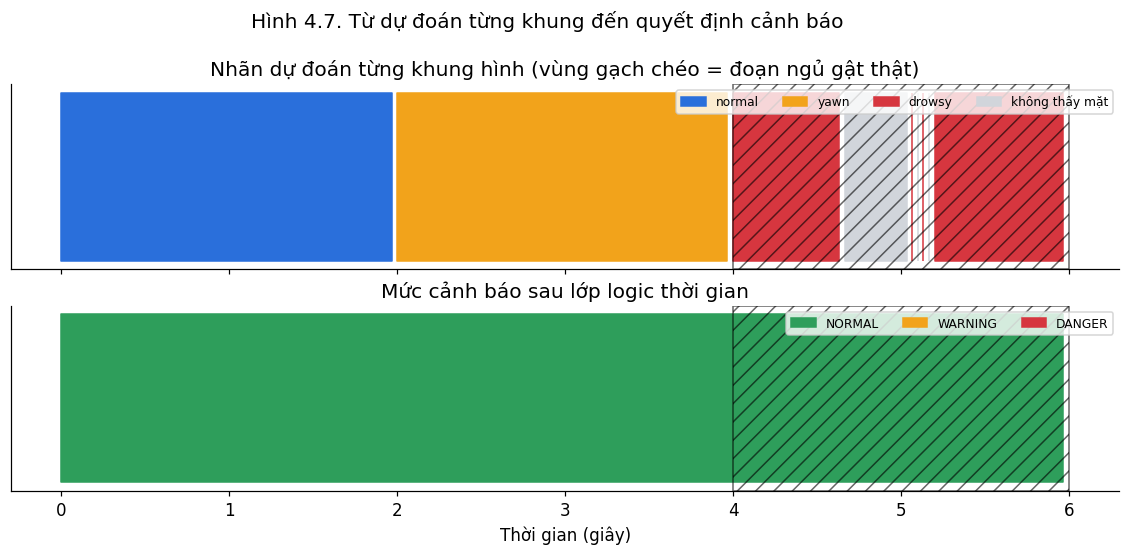

,Số lần ngủ gật diễn lại,Số lần được cảnh báo,Số báo động giả,Báo động giả / phút,Độ trễ phát hiện TB (giây)
Chuỗi kiểm thử dựng từ tập test,1,0,0,0.0,NaN


Đã lưu bảng: /content/drive/MyDrive/drowsiness_yolov8/report_assets/bang_4_6_he_thong.csv
Đã lưu bảng: /content/drive/MyDrive/drowsiness_yolov8/report_assets/dong_thoi_gian_chuoi_test.csv
Số lần bật cảnh báo mức cao: không làm mượt (báo ngay khi 1 khung là drowsy) = 4, có logic thời gian = 0 (đáp án đúng: 1 đoạn ngủ gật)


NameError: name 'HTML' is not defined

In [ ]:
# 11.3 TỰ ĐỘNG: dựng một video kiểm thử từ các khung thuộc tập TEST (mô hình chưa từng thấy khi huấn luyện),
# xen kẽ các đoạn normal / yawn / drowsy theo thứ tự thời gian, rồi đo hệ thống cảnh báo với đáp án đúng đã biết (mục 4.9)
def build_test_sequence(out_path='/content/test_sequence.mp4', max_side=960):
    if 't_sec' not in img_df.columns or img_df.t_sec.isna().any():
        print('Dữ liệu không đến từ video (không có mốc thời gian): bỏ qua ô này. Hãy dùng ô 11.4 với video của bạn.')
        return None, None, None
    te = img_df[img_df.split == 'test'].copy()
    te['blk'] = (te.t_sec // BLOCK_SEC).astype(int)
    pools = {c: [] for c in CLASS_NAMES}
    for (vid, b), g in te.groupby(['video', 'blk']):
        pools[g.class_name.iloc[0]].append(g.sort_values('t_sec'))
    order = []
    while any(pools.values()):
        for c in ['normal', 'yawn', 'normal', 'drowsy']:
            if pools[c]:
                order.append((c, pools[c].pop(0)))
    fps = float(te.samp_fps.median())
    first = cv2.imread(str(WORK / 'test' / 'images' / order[0][1].image.iloc[0]))
    sc = min(1.0, max_side / max(first.shape[:2]))
    W, H = int(first.shape[1] * sc) // 2 * 2, int(first.shape[0] * sc) // 2 * 2
    writer = cv2.VideoWriter(out_path, cv2.VideoWriter_fourcc(*'mp4v'), fps, (W, H))
    gt, n_written = [], 0
    for c, g in order:
        t0 = n_written / fps
        for name in g.image:
            writer.write(cv2.resize(cv2.imread(str(WORK / 'test' / 'images' / name)), (W, H)))
            n_written += 1
        if c == 'drowsy':
            gt.append((t0, n_written / fps))
    writer.release()
    print(f'Video kiểm thử: {n_written} khung, {n_written / fps:.1f} giây ở {fps:.1f} khung/giây, {len(order)} đoạn, {len(gt)} đoạn ngủ gật (đáp án).')
    return out_path, gt, fps

seq_path, GT_SEQ, seq_fps = build_test_sequence()
if seq_path:
    tl_seq, _ = process_video(seq_path, '/content/test_seq_alert.mp4', best_model, use_clahe=False)
    plot_timeline(tl_seq, 'hinh_4_7_dong_thoi_gian', gt=GT_SEQ)
    sys_tbl = pd.DataFrame([eval_alerts(tl_seq, GT_SEQ)], index=['Chuỗi kiểm thử dựng từ tập test'])
    display(sys_tbl)
    save_table(sys_tbl, 'bang_4_6_he_thong')
    RESULTS['system'] = sys_tbl
    save_table(tl_seq, 'dong_thoi_gian_chuoi_test', index=False)
    naive_eps = int(((tl_seq.label == 'drowsy').astype(int).diff().fillna(0) == 1).sum())
    print(f'Số lần bật cảnh báo mức cao: không làm mượt (báo ngay khi 1 khung là drowsy) = {naive_eps}, có logic thời gian = {len(episodes(tl_seq))} '
          f'(đáp án đúng: {len(GT_SEQ)} đoạn ngủ gật)')
    show_video('/content/test_seq_alert.mp4')

In [ ]:
# 11.4 Chạy trên video RIÊNG của bạn (tùy chọn): quay bằng webcam (record_clip) hoặc tải video lên
# Cách 1: quay 40 giây (nên diễn: bình thường -> ngáp -> bình thường -> ngủ gật -> bình thường)
# record_clip(40, '/content/test_clip.webm'); VIDEO = '/content/test_clip.webm'
# Cách 2: tải video lên
# from google.colab import files; up = files.upload(); VIDEO = '/content/' + list(up)[0]
VIDEO = None          # <-- gán đường dẫn video vào đây

# Các đoạn bạn ĐÃ DIỄN ngủ gật (tính bằng giây từ đầu video) để đo độ trễ và báo động giả. Ví dụ: [(18, 26), (40, 48)]
GT_DROWSY_INTERVALS = []

if VIDEO:
    tl, fps = process_video(VIDEO, '/content/alert_out.mp4', best_model, max_seconds=120)
    plot_timeline(tl)
    show_video('/content/alert_out.mp4')
    save_table(tl, 'dong_thoi_gian_video', index=False)
    if GT_DROWSY_INTERVALS:
        sys_tbl = pd.DataFrame([eval_alerts(tl, GT_DROWSY_INTERVALS)], index=['Video kiểm thử'])
        display(sys_tbl)
        save_table(sys_tbl, 'bang_4_6_he_thong')
        RESULTS['system'] = sys_tbl
    # So sánh có/không lớp làm mượt: cảnh báo ngay khi 1 khung là drowsy
    naive = tl.label.eq('drowsy').astype(int)
    naive_eps = sum(1 for a, b in zip(naive.shift(fill_value=0), naive) if b == 1 and a == 0)
    smooth_eps = len(episodes(tl))
    print(f'Số lần bật cảnh báo mức cao: không làm mượt = {naive_eps}, có làm mượt = {smooth_eps}')
else:
    print('Chưa có video. Gán VIDEO ở trên rồi chạy lại ô này.')

Chưa có video. Gán VIDEO ở trên rồi chạy lại ô này.


## Phần 12. Giao diện demo Gradio (mục 4.8)

Ba tab: **Ảnh** (thanh trượt conf/iou, bảng kết quả), **Video** (có logic cảnh báo), **Webcam trực tiếp** (cảnh báo xanh/vàng/đỏ).
Đường dẫn `share=True` công khai tạm thời để giảng viên mở trên trình duyệt của họ; chỉ hoạt động khi notebook còn chạy.

In [ ]:
import gradio as gr

demo_model = YOLO(str(BEST))

def status_html(level, info=None):
    extra = f" · drowsy {info['drowsy_ratio']:.0%} · ngáp/60s: {info['yawn_events']}" if info else ''
    msg = {'NORMAL': 'Bình thường', 'WARNING': 'Cảnh báo: có dấu hiệu mệt mỏi', 'DANGER': 'NGUY HIỂM: đang ngủ gật!'}[level]
    return f'<div style="padding:14px;border-radius:10px;background:{LEVEL_HEX[level]};color:white;font-size:20px;font-weight:600">{msg}{extra}</div>'

def predict_image(img, conf, iou, use_clahe):
    empty = pd.DataFrame(columns=['Lớp', 'Độ tin cậy', 'Hộp (x1,y1,x2,y2)'])
    if img is None:
        return None, empty
    bgr = np.ascontiguousarray(img[..., ::-1])                  # Gradio trả RGB, Ultralytics coi numpy là BGR
    if use_clahe:
        bgr = apply_clahe(bgr)
    r = demo_model.predict(bgr, conf=conf, iou=iou, imgsz=IMGSZ, device=DEVICE, verbose=False)[0]
    table = pd.DataFrame([[CLASS_NAMES[int(b.cls)], round(float(b.conf), 3), [int(v) for v in b.xyxy[0].tolist()]] for b in r.boxes],
                         columns=['Lớp', 'Độ tin cậy', 'Hộp (x1,y1,x2,y2)'])
    return np.ascontiguousarray(r.plot()[..., ::-1]), table

def predict_video(path, conf, use_clahe):
    if not path:
        return None, 'Hãy tải video lên.'
    out = '/content/demo_out.mp4'
    tl, fps = process_video(path, out, demo_model, conf=conf, use_clahe='auto' if use_clahe else False, max_seconds=60)
    h264 = '/content/demo_out_h264.mp4'
    subprocess.run(['ffmpeg', '-y', '-loglevel', 'error', '-i', out, '-vcodec', 'libx264', '-pix_fmt', 'yuv420p', h264])
    summary = (f"Thời lượng xử lý: {tl.t.iloc[-1]:.1f} giây | số đoạn cảnh báo NGUY HIỂM: {len(episodes(tl))} | "
               f"tổng thời gian NGUY HIỂM: {(tl.level == 'DANGER').mean() * tl.t.iloc[-1]:.1f} giây")
    return h264, summary

STREAM_EVERY = 0.2          # giây giữa hai khung hình webcam gửi lên

def stream_frame(frame, conf, state):
    if frame is None:
        return None, status_html('NORMAL'), state
    if state is None:
        state = {'alert': TemporalAlert(fps=1 / STREAM_EVERY), 't0': time.time()}
    bgr = np.ascontiguousarray(frame[..., ::-1])
    res = demo_model.predict(bgr, conf=conf, imgsz=IMGSZ, device=DEVICE, verbose=False)[0]
    label, c, box = pick_main_detection(res)
    level, info = state['alert'].update(label, time.time() - state['t0'])
    out = draw_overlay(bgr, label, c, box, level, info)
    return out[..., ::-1], status_html(level, info), state

with gr.Blocks(title='Hệ thống Phát hiện Ngủ gật - YOLOv8 Demo') as demo:
    gr.Markdown('# Hệ thống Phát hiện Ngủ gật - YOLOv8 Demo\nĐồ án môn Xử Lí Ảnh. Ba lớp: **normal**, **yawn**, **drowsy**.')
    with gr.Tab('Ảnh'):
        with gr.Row():
            with gr.Column():
                in_img = gr.Image(type='numpy', label='Ảnh đầu vào')
                conf_s = gr.Slider(0.05, 1.0, value=CONF_INFER, label='Confidence Threshold')
                iou_s = gr.Slider(0.1, 1.0, value=0.7, label='IoU (NMS)')
                clahe_c = gr.Checkbox(label='Bật CLAHE (cho ảnh thiếu sáng)')
                btn = gr.Button('Phát hiện', variant='primary')
            with gr.Column():
                out_img = gr.Image(type='numpy', label='Kết quả')
                out_tbl = gr.Dataframe(label='Chi tiết từng khuôn mặt')
        btn.click(predict_image, [in_img, conf_s, iou_s, clahe_c], [out_img, out_tbl])
    with gr.Tab('Video'):
        in_vid = gr.Video(label='Video đầu vào (xử lý tối đa 60 giây)')
        conf_v = gr.Slider(0.05, 1.0, value=CONF_INFER, label='Confidence Threshold')
        clahe_v = gr.Checkbox(label='CLAHE có điều kiện khi khung hình tối', value=True)
        btn_v = gr.Button('Phân tích video', variant='primary')
        out_vid = gr.Video(label='Video kết quả')
        out_txt = gr.Textbox(label='Tóm tắt')
        btn_v.click(predict_video, [in_vid, conf_v, clahe_v], [out_vid, out_txt])
    with gr.Tab('Webcam trực tiếp'):
        gr.Markdown('Cho phép trình duyệt dùng camera. Mức cảnh báo cập nhật theo thời gian thực.')
        cam = gr.Image(sources=['webcam'], streaming=True, type='numpy', label='Webcam')
        conf_w = gr.Slider(0.05, 1.0, value=CONF_INFER, label='Confidence Threshold')
        banner = gr.HTML(status_html('NORMAL'))
        out_w = gr.Image(type='numpy', label='Kết quả')
        state = gr.State(None)
        cam.stream(stream_frame, [cam, conf_w, state], [out_w, banner, state], stream_every=STREAM_EVERY, time_limit=300)

demo.queue().launch(share=True, debug=False)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://f5cd2286651a7ebb7d.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


## Phần 13. Xuất mô hình, lưu kết quả và tạo bản tóm tắt để dán vào báo cáo

In [ ]:
# 13.1 Lưu best.pt, xuất ONNX, ghi requirements.txt
shutil.copy2(BEST, MODELS / 'best.pt')
try:
    onnx_path = YOLO(str(BEST)).export(format='onnx', imgsz=IMGSZ, opset=12)
    shutil.copy2(onnx_path, MODELS / 'best.onnx')
    print('Đã xuất ONNX:', MODELS / 'best.onnx')
except Exception as e:
    print('Không xuất được ONNX (không ảnh hưởng báo cáo):', e)

keep = ('ultralytics', 'torch', 'torchvision', 'opencv-python', 'gradio', 'numpy', 'pandas', 'matplotlib', 'pillow')
frozen = subprocess.run([sys.executable, '-m', 'pip', 'freeze'], capture_output=True, text=True).stdout.splitlines()
req = [l for l in frozen if l.lower().split('==')[0] in keep]
(ROOT / 'requirements.txt').write_text('\n'.join(req) + '\n')
print('requirements.txt:\n' + '\n'.join(req))

Ultralytics 8.4.202 🚀 Python-3.13.16 torch-2.11.0+cu130 CPU (Intel Xeon CPU @ 2.00GHz)
💡 ProTip: Export to OpenVINO format for best performance on Intel hardware. Learn more at https://docs.ultralytics.com/integrations/openvino
Model summary (fused): 73 layers, 3,133,193 parameters, 0 gradients, 8.6 GFLOPs

PyTorch: starting from '/content/drive/MyDrive/drowsiness_yolov8/runs/ngu_gat_yolov8n/weights/best.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 7, 8400) (6.2 MB)
requirements: Ultralytics requirements ['onnx>=1.12.0,<2.0.0', 'onnxruntime', 'onnxslim>=0.1.82'] not found, attempting AutoUpdate...
Using Python 3.13.16 environment at: /usr
Resolved 12 packages in 301ms
Prepared 4 packages in 1.66s
Installed 4 packages in 39ms
 + colorama==0.4.6
 + onnx==1.23.2
 + onnxruntime==1.31.1
 + onnxslim==0.1.99

requirements: AutoUpdate success ✅ 2.3s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect


ONNX: starting export with onnx 1.23.

In [ ]:
# 13.2 Tạo results_summary.md: mọi bảng đã đo, định dạng sẵn để dán vào các ô [ĐIỀN] của báo cáo
def md(df):
    try:
        return df.to_markdown()
    except Exception:
        return df.to_string()

parts = ['# Tóm tắt kết quả thực nghiệm (tự sinh từ notebook)\n',
         '## Môi trường (Bảng 3.1)\n', md(pd.Series(ENV_INFO, name='Giá trị').to_frame()), '']
sections = [
    ('dataset_summary', 'Thống kê bộ dữ liệu (Bảng 2.1)'), ('brightness', 'Độ sáng theo lớp (Bảng 2.2)'),
    ('leakage', 'Rò rỉ dữ liệu: chia ngẫu nhiên và chia theo phiên'), ('split', 'Chia tập'),
    ('overall', 'Kết quả tổng hợp (Bảng 4.1)'), ('per_class', 'Kết quả theo lớp (Bảng 4.2)'),
    ('ablation', 'Thí nghiệm đối chứng (Bảng 4.3)'), ('speed', 'Tốc độ và kích thước (Bảng 4.4)'),
    ('clahe', 'Ảnh hưởng của CLAHE (Bảng 4.5)'), ('err_by_brightness', 'Tỷ lệ lỗi theo mức sáng'),
    ('system', 'Đánh giá cấp hệ thống (mục 4.9)'),
]
for key, title in sections:
    if key in RESULTS:
        parts += [f'## {title}\n', md(RESULTS[key]), '']
parts += [f"## Thông số khác\n\n- Epoch tốt nhất: {RESULTS.get('best_epoch', '?')}\n- Ngưỡng conf chọn theo F1: {RESULTS.get('conf_best', CONF_INFER):.3f}\n- Hạt giống: {SEED}\n"]
summary_md = '\n'.join(parts)
(OUT / 'results_summary.md').write_text(summary_md, encoding='utf-8')
print(summary_md[:3000])
print('\nĐã lưu:', OUT / 'results_summary.md')

# Tóm tắt kết quả thực nghiệm (tự sinh từ notebook)

## Môi trường (Bảng 3.1)

|             | Giá trị      |
|:------------|:-------------|
| Python      | 3.13.16      |
| PyTorch     | 2.11.0+cu130 |
| Ultralytics | 8.4.202      |
| OpenCV      | 4.14.0       |
| GPU         | Tesla T4     |
| CUDA        | 13.0         |

## Thống kê bộ dữ liệu (Bảng 2.1)

|        |   Số ảnh |   Số hộp |   Rộng TB (chuẩn hóa) |   Cao TB (chuẩn hóa) |
|:-------|---------:|---------:|----------------------:|---------------------:|
| normal |      673 |      673 |                 0.191 |                0.487 |
| yawn   |      696 |      696 |                 0.213 |                0.568 |
| drowsy |      703 |      703 |                 0.213 |                0.528 |
| Tổng   |     2072 |     2072 |               nan     |              nan     |

## Độ sáng theo lớp (Bảng 2.2)

| class_name   |   Độ sáng TB |   Độ lệch chuẩn |   % ảnh tối (V<60) |   % ảnh cháy sáng (V>200) |
|:-------------|---------

In [ ]:
# 13.3 (Tùy chọn) Nén toàn bộ hình/bảng để tải về máy
shutil.make_archive('/content/report_assets', 'zip', OUT)
from google.colab import files
files.download('/content/report_assets.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Phụ lục: ánh xạ ô trong notebook → ô [ĐIỀN]/[CHÈN] trong báo cáo

| Mục báo cáo | Lấy từ file trong `report_assets/` |
|---|---|
| Bảng 2.1, Biểu đồ 2.1, 2.2 | `bang_2_1_thong_ke_du_lieu.csv`, `bieu_do_2_1_phan_bo_lop.png`, `bieu_do_2_2_vi_tri_kich_thuoc_hop.png` |
| Bảng độ sáng, Biểu đồ 2.3 | `bang_2_2_do_sang_theo_lop.csv`, `bieu_do_2_3_histogram_do_sang.png` |
| Hình 2.4, 2.6 | `hinh_2_4_clahe_truoc_sau.png`, `hinh_2_6_hsv_kenh.png` |
| Mục 2.6 (rò rỉ, chia tập) | `bang_2_3_ro_ri_du_lieu.csv`, `bang_chia_tap.csv`, `bieu_do_chia_tap.png` |
| Biểu đồ 4.1 | `bieu_do_4_1_huan_luyen.png` |
| Bảng 4.1, 4.2 | `bang_4_1_tong_hop.csv`, `bang_4_2_theo_lop.csv` |
| Hình 4.1, 4.2 | `hinh_4_1_ma_tran_nham_lan.png`, `hinh_4_2_duong_cong.png` |
| Hình 4.3, 4.5, bảng lỗi | `hinh_4_3_truoc_sau.png`, `hinh_4_5_loi_tieu_bieu.png`, `danh_sach_loi.csv`, `bieu_do_ty_le_loi.png` |
| Bảng 4.3 | `bang_4_3_doi_chung.csv` (nếu bật Phần 9) |
| Bảng 4.4 | `bang_4_4_toc_do.csv` |
| Bảng 4.5 | `bang_4_5_clahe.csv`, `bieu_do_4_clahe.png` |
| Mục 4.9, Hình 4.7 | `bang_4_6_he_thong.csv`, `hinh_4_7_dong_thoi_gian.png` |
| Ảnh demo Gradio (Hình 4.6) | tự chụp màn hình giao diện ở Phần 12 |